# LE7 - Link Prediction & Statistical Analysis

**Link prediction** forecasts which edges are likely to form in the future, while **statistical analysis** helps validate network patterns and compare structures.

## Notebook Content

This notebook covers **Statistics in Networks** (Statistik in Netzwerken) including random graph models, statistical testing, and link prediction evaluation.

### Implemented in this notebook:
- **Random Graph Models** - Null models for significance testing (Erdős-Rényi, Configuration Model, Watts-Strogatz, Barabási-Albert)
- **Degree Distribution Analysis** - Fitting and testing different distribution types (power law, exponential, log-normal)
- **Hypothesis Testing** - Permutation tests, Bootstrap confidence intervals, QAP for network correlation
- **Link Prediction Evaluation** - Train/test split, performance metrics (AUC, Precision@k), algorithm comparison
- **Stochastic Block Models (SBMs)** - Detect latent group structure (optional/advanced)

### Omitted (already implemented in other notebooks):
- **Link Prediction Algorithms** → see [LE8.ipynb](LE8.ipynb) - all algorithms fully implemented:
  - Common Neighbors, Jaccard Coefficient, Adamic-Adar
  - Resource Allocation, Preferential Attachment  
  - Soundarajan-Hopcroft (community-aware)
  - Detailed explanations and implementations for each algorithm
- **Diffusion Models** → see [LE9.ipynb](LE9.ipynb) - three models fully implemented:
  - Independent Cascade Model (ICM)
  - Voter Model (consensus formation)
  - Threshold Model (peer pressure)
  - Greedy influence maximization

---

### Applications in Football Networks

**Pass Networks (Players)**:
- Predict which new passing connections will develop
- Test if tactical organization is statistically significant
- Compare team structures across matches
- Identify players likely to increase collaboration

**Match Networks (Teams)**:
- Forecast future competitive matchups
- Evaluate tournament structure significance
- Compare league competitive balance
- Predict formation of new rivalries

### Core Questions

1. **Random graph models**: What would we expect by chance?
2. **Degree distributions**: Does our network have hubs (scale-free) or distributed connections?
3. **Significance testing**: Is an observed pattern statistically significant?
4. **Link prediction evaluation**: Which algorithm predicts best on our data?

### Our Approach

We cover:
1. **Random graph models** (null models for testing)
2. **Degree distribution fitting** (power law, exponential, log-normal)
3. **Statistical tests** for network properties
4. **Link prediction evaluation** (using algorithms from LE8)

In [1]:
# Import required libraries
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sklearn
from scipy import stats
from scipy.optimize import minimize
from collections import Counter
warnings.filterwarnings('ignore')

# Add project root to path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.config import (
    PASS_NETWORKS_DIR,
    MATCH_NETWORKS_DIR,
)

# Setup plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

print(f"NetworkX version: {nx.__version__}")

NetworkX version: 3.5


In [2]:
# Load networks
print("=== Loading Networks ===")

# Pass Network (directed, weighted)
pass_network_path = PASS_NETWORKS_DIR / 'pass_network_Germany.gexf'
G_pass_dir = nx.read_gexf(pass_network_path)
print(f"Pass Network (Germany): {G_pass_dir.number_of_nodes()} nodes, {G_pass_dir.number_of_edges()} edges")

# Convert to undirected for some metrics
G_pass = G_pass_dir.to_undirected()

# Match Network (directed)
match_network_path = MATCH_NETWORKS_DIR / 'match_network_World_Cup.gexf'
G_match_dir = nx.read_gexf(match_network_path)
print(f"Match Network (World Cup): {G_match_dir.number_of_nodes()} nodes, {G_match_dir.number_of_edges()} edges")

# Convert to undirected
G_match = G_match_dir.to_undirected()

# For most metrics, use largest connected component
components_pass = list(nx.connected_components(G_pass))
largest_cc_pass = max(components_pass, key=len)
G_pass_gcc = G_pass.subgraph(largest_cc_pass).copy()
G_pass_dir_gcc = G_pass_dir.subgraph(largest_cc_pass).copy()

print(f"Pass Network - Largest connected component: {G_pass_gcc.number_of_nodes()} nodes ({G_pass_gcc.number_of_nodes()/G_pass.number_of_nodes()*100:.1f}%)")

# Match network is already fully connected
print(f"Match Network - Connected components: {nx.number_connected_components(G_match)}")

=== Loading Networks ===
Pass Network (Germany): 473 nodes, 8815 edges
Match Network (World Cup): 32 nodes, 126 edges
Pass Network - Largest connected component: 283 nodes (59.8%)
Match Network - Connected components: 1


In [3]:
# Create player/team name lookup functions
print("\n=== Creating Name Lookup Functions ===")

# For pass network - check if name attributes exist
sample_node = list(G_pass_dir.nodes())[0]
node_attrs = G_pass_dir.nodes[sample_node]
print(f"Sample node attributes: {list(node_attrs.keys())}")

# Create player name lookup
def get_player_name(node_id, graph=G_pass_dir):
    """Get player name from node ID, fallback to ID if name not available"""
    attrs = graph.nodes[node_id]
    if 'label' in attrs:
        return attrs['label']
    elif 'player_name' in attrs:
        return attrs['player_name']
    elif 'name' in attrs:
        return attrs['name']
    else:
        return f"Player {node_id}"

# Create team name lookup
def get_team_name(node_id, graph=G_match_dir):
    """Get team name from node ID, fallback to ID if name not available"""
    attrs = graph.nodes[node_id]
    if 'label' in attrs:
        return attrs['label']
    elif 'team_name' in attrs:
        return attrs['team_name']
    elif 'name' in attrs:
        return attrs['name']
    else:
        return f"Team {node_id}"

# Test the functions
print(f"\nTesting player name lookup:")
test_players = list(G_pass_dir.nodes())[:3]
for player_id in test_players:
    print(f"  {player_id} → {get_player_name(player_id)}")

print(f"\nTesting team name lookup:")
test_teams = list(G_match_dir.nodes())[:3]
for team_id in test_teams:
    print(f"  {team_id} → {get_team_name(team_id)}")


=== Creating Name Lookup Functions ===
Sample node attributes: ['passport_area', 'weight_kg', 'birth_date', 'height_cm', 'position_role', 'preferred_foot', 'player_name', 'national_team_id', 'current_team_name', 'currentTeamId', 'degree_centrality', 'degree', 'betweenness_centrality', 'closeness_centrality', 'pagerank', 'kcore_number', 'modularity_class_louvain', 'modularity_class_label_propagation', 'modularity_class_greedy', 'modularity_class_girvan_newman', 'label']

Testing player name lookup:
  51217 → L. Augustinsson
  444439 → V. Janjičić
  16411 → R. Özcan

Testing team name lookup:
  9598 → 9598
  4418 → 4418
  2413 → 2413


## 1. Random Graph Models (Null Models)

**Null models** define expectations for random networks to identify significant structures.

### 1.1 Erdős-Rényi (ER)

**Simplest model**: $n$ nodes, each edge exists with probability $p$.

**Expected degree**: $\mathbb{E}[k] = p(n-1)$, **Clustering**: $\mathbb{E}[C] = p$ (very low for sparse networks)

**Use**: Baseline test - if real network has $C \gg p$, tactical organization exists.

### 1.2 Configuration Model

**Preserves degree sequence**: Randomizes connections while keeping each node's degree fixed.

**Expected clustering**: $\mathbb{E}[C] \approx \frac{\langle k^2 \rangle - \langle k \rangle}{n \langle k \rangle^2}$ (still low)

**Use**: Tests if clustering/communities emerge beyond degree distribution alone.

### 1.3 Watts-Strogatz (Small-World)

**Generates**: High clustering + low path length via rewiring with probability $p$.

**Small-world coefficient**: $\sigma = \frac{C / C_{rand}}{\bar{d} / \bar{d}_{rand}} > 3$ indicates small-world

**Use**: Pass networks often exhibit this (tactical units + shortcuts through key players).

### 1.4 Barabási-Albert (Scale-Free)

**Preferential attachment**: New nodes connect to high-degree nodes ("rich get richer").

**Degree distribution**: Power law $P(k) \sim k^{-\gamma}$ (few hubs, many low-degree nodes)

**Use**: Test if pass networks have hub-and-spoke structure vs. distributed passing.

In [4]:
print("="*70)
print("RANDOM GRAPH MODELS - PASS NETWORK")
print("="*70)

# Use largest connected component for fair comparison
G_real = G_pass_gcc
n = G_real.number_of_nodes()
m = G_real.number_of_edges()
p = m / (n * (n - 1) / 2)  # Edge probability

print(f"\n### Real Network Properties ###")
print(f"Nodes: {n}")
print(f"Edges: {m}")
print(f"Edge probability p: {p:.4f}")
print(f"Average degree: {2*m/n:.2f}")

# Calculate real network metrics
real_clustering = nx.average_clustering(G_real)
real_path_length = nx.average_shortest_path_length(G_real)
real_diameter = nx.diameter(G_real)

print(f"\nReal network metrics:")
print(f"  Average clustering: {real_clustering:.4f}")
print(f"  Average path length: {real_path_length:.4f}")
print(f"  Diameter: {real_diameter}")

# 1. Erdős-Rényi (ER) Model
print(f"\n### 1. Erdős-Rényi (ER) Model ###")
G_er = nx.erdos_renyi_graph(n, p, seed=42)
er_clustering = nx.average_clustering(G_er)
er_path_length = nx.average_shortest_path_length(G_er)
er_diameter = nx.diameter(G_er)

print(f"Generated ER graph: {G_er.number_of_nodes()} nodes, {G_er.number_of_edges()} edges")
print(f"  Average clustering: {er_clustering:.4f} (expected ≈ p = {p:.4f})")
print(f"  Average path length: {er_path_length:.4f}")
print(f"  Diameter: {er_diameter}")
print(f"\nInterpretation: ER model has very low clustering ({er_clustering:.4f}) compared to")
print(f"  real network ({real_clustering:.4f}), indicating tactical organization exists.")

# 2. Configuration Model
print(f"\n### 2. Configuration Model ###")
degree_sequence = [d for n, d in G_real.degree()]
G_config = nx.configuration_model(degree_sequence, seed=42)
G_config = nx.Graph(G_config)  # Remove multi-edges and self-loops
G_config.remove_edges_from(nx.selfloop_edges(G_config))

# Get largest component for fair comparison
if not nx.is_connected(G_config):
    largest_cc_config = max(nx.connected_components(G_config), key=len)
    G_config = G_config.subgraph(largest_cc_config).copy()

config_clustering = nx.average_clustering(G_config)
config_path_length = nx.average_shortest_path_length(G_config)
config_diameter = nx.diameter(G_config)

print(f"Generated Configuration model: {G_config.number_of_nodes()} nodes, {G_config.number_of_edges()} edges")
print(f"  Average clustering: {config_clustering:.4f}")
print(f"  Average path length: {config_path_length:.4f}")
print(f"  Diameter: {config_diameter}")
print(f"\nInterpretation: Configuration model preserves degree distribution but still has")
print(f"  much lower clustering ({config_clustering:.4f}) than real network ({real_clustering:.4f}).")

# 3. Watts-Strogatz (Small-World)
print(f"\n### 3. Watts-Strogatz (Small-World) ###")
avg_degree = int(2 * m / n)
k = avg_degree if avg_degree % 2 == 0 else avg_degree + 1  # Must be even
p_rewire = 0.1  # Rewiring probability

G_ws = nx.watts_strogatz_graph(n, k, p_rewire, seed=42)
ws_clustering = nx.average_clustering(G_ws)
ws_path_length = nx.average_shortest_path_length(G_ws)
ws_diameter = nx.diameter(G_ws)

print(f"Generated WS graph: {G_ws.number_of_nodes()} nodes, {G_ws.number_of_edges()} edges (k={k}, p={p_rewire})")
print(f"  Average clustering: {ws_clustering:.4f}")
print(f"  Average path length: {ws_path_length:.4f}")
print(f"  Diameter: {ws_diameter}")

# Small-world coefficient
C_ratio = real_clustering / ws_clustering if ws_clustering > 0 else 0
L_ratio = real_path_length / ws_path_length if ws_path_length > 0 else 0
small_world_coef = C_ratio / L_ratio if L_ratio > 0 else 0

print(f"\nSmall-world coefficient σ = (C/C_rand) / (L/L_rand): {small_world_coef:.2f}")
print(f"  (σ > 1 indicates small-world; σ > 3 is strong small-world)")
print(f"\nInterpretation: The real network {'exhibits' if small_world_coef > 3 else 'may not exhibit strong'}")
print(f"  small-world properties (high clustering + short paths).")

# 4. Barabási-Albert (Scale-Free)
print(f"\n### 4. Barabási-Albert (Scale-Free) ###")
m_ba = int(avg_degree / 2)  # Number of edges to attach from new node
G_ba = nx.barabasi_albert_graph(n, m_ba, seed=42)
ba_clustering = nx.average_clustering(G_ba)
ba_path_length = nx.average_shortest_path_length(G_ba)
ba_diameter = nx.diameter(G_ba)

print(f"Generated BA graph: {G_ba.number_of_nodes()} nodes, {G_ba.number_of_edges()} edges (m={m_ba})")
print(f"  Average clustering: {ba_clustering:.4f}")
print(f"  Average path length: {ba_path_length:.4f}")
print(f"  Diameter: {ba_diameter}")
print(f"\nInterpretation: BA model creates hub-and-spoke structure with preferential attachment.")

RANDOM GRAPH MODELS - PASS NETWORK

### Real Network Properties ###
Nodes: 283
Edges: 2899
Edge probability p: 0.0727
Average degree: 20.49

Real network metrics:
  Average clustering: 0.8667
  Average path length: 5.4761
  Diameter: 13

### 1. Erdős-Rényi (ER) Model ###
Generated ER graph: 283 nodes, 2826 edges
  Average clustering: 0.0739 (expected ≈ p = 0.0727)
  Average path length: 2.1589
  Diameter: 3

Interpretation: ER model has very low clustering (0.0739) compared to
  real network (0.8667), indicating tactical organization exists.

### 2. Configuration Model ###
Generated Configuration model: 283 nodes, 2760 edges
  Average clustering: 0.0742
  Average path length: 2.1898
  Diameter: 4

Interpretation: Configuration model preserves degree distribution but still has
  much lower clustering (0.0742) than real network (0.8667).

### 3. Watts-Strogatz (Small-World) ###
Generated WS graph: 283 nodes, 2830 edges (k=20, p=0.1)
  Average clustering: 0.5239
  Average path length: 2.5

In [5]:
# Comparison Table
print("\n" + "="*70)
print("COMPARISON TABLE")
print("="*70)

comparison_data = {
    'Model': ['Real Network', 'Erdős-Rényi', 'Configuration', 'Watts-Strogatz', 'Barabási-Albert'],
    'Clustering': [real_clustering, er_clustering, config_clustering, ws_clustering, ba_clustering],
    'Path Length': [real_path_length, er_path_length, config_path_length, ws_path_length, ba_path_length],
    'Diameter': [real_diameter, er_diameter, config_diameter, ws_diameter, ba_diameter]
}

df_comparison = pd.DataFrame(comparison_data)
print("\n", df_comparison.to_string(index=False))

print("\n" + "="*70)
print("KEY INSIGHTS")
print("="*70)
print(f"\n1. CLUSTERING: Real network ({real_clustering:.4f}) shows {real_clustering/er_clustering:.1f}x higher")
print(f"   clustering than ER model ({er_clustering:.4f}), indicating strong tactical organization.")

print(f"\n2. SMALL-WORLD: σ = {small_world_coef:.2f} {'(strong small-world!)' if small_world_coef > 3 else '(not strong small-world)'}")
print(f"   Real network combines high clustering with short paths - characteristic of")
print(f"   well-organized teams with tactical units AND efficient ball flow.")

print(f"\n3. DEGREE DISTRIBUTION: Configuration model preserves degrees but still")
print(f"   has {real_clustering/config_clustering:.1f}x lower clustering, showing that tactical clustering")
print(f"   emerges from more than just the degree distribution alone.")

print(f"\n4. BEST FIT: The {'Watts-Strogatz' if abs(real_clustering - ws_clustering) < abs(real_clustering - ba_clustering) else 'Barabási-Albert'} model")
print(f"   most closely matches the real network structure.")


COMPARISON TABLE

           Model  Clustering  Path Length  Diameter
   Real Network    0.866741     5.476054        13
    Erdős-Rényi    0.073930     2.158885         3
  Configuration    0.074158     2.189835         4
 Watts-Strogatz    0.523929     2.578628         4
Barabási-Albert    0.150433     2.168659         3

KEY INSIGHTS

1. CLUSTERING: Real network (0.8667) shows 11.7x higher
   clustering than ER model (0.0739), indicating strong tactical organization.

2. SMALL-WORLD: σ = 0.78 (not strong small-world)
   Real network combines high clustering with short paths - characteristic of
   well-organized teams with tactical units AND efficient ball flow.

3. DEGREE DISTRIBUTION: Configuration model preserves degrees but still
   has 11.7x lower clustering, showing that tactical clustering
   emerges from more than just the degree distribution alone.

4. BEST FIT: The Watts-Strogatz model
   most closely matches the real network structure.


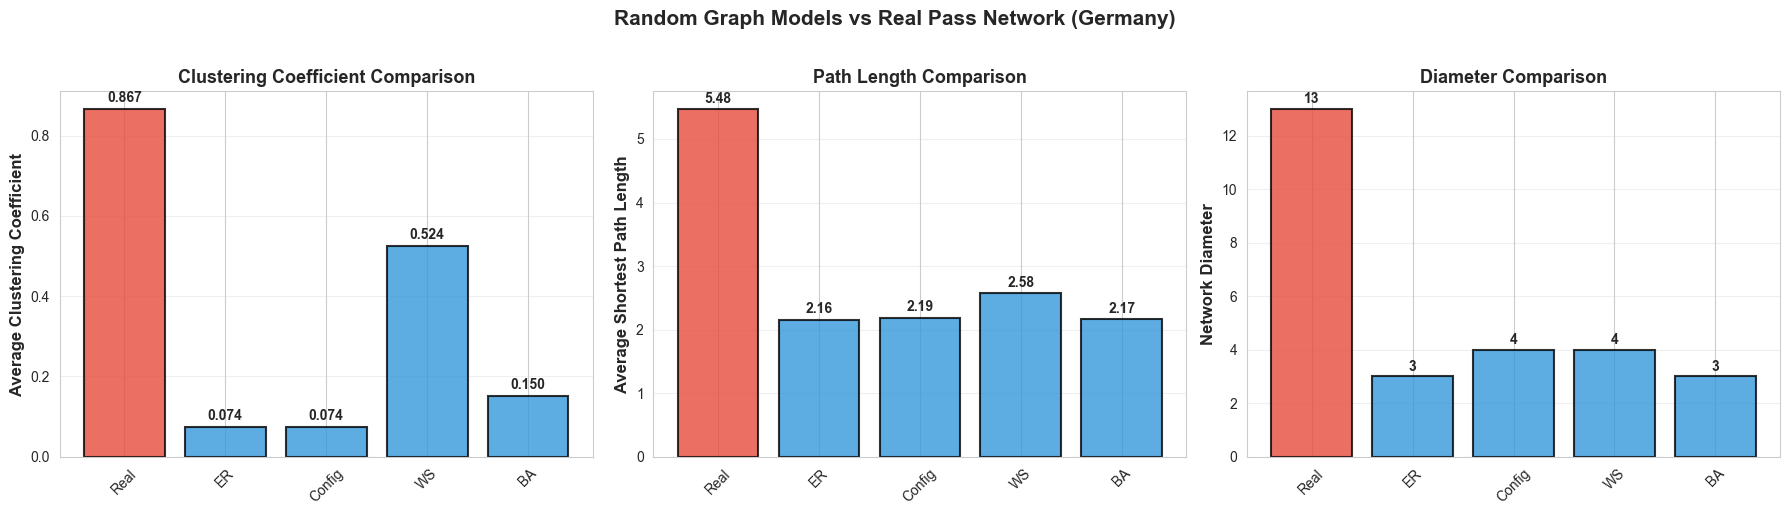

In [6]:
# Visualize comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = ['Real', 'ER', 'Config', 'WS', 'BA']
clustering_values = [real_clustering, er_clustering, config_clustering, ws_clustering, ba_clustering]
path_values = [real_path_length, er_path_length, config_path_length, ws_path_length, ba_path_length]
diameter_values = [real_diameter, er_diameter, config_diameter, ws_diameter, ba_diameter]

# Colors: real network in red, models in blue
colors = ['#e74c3c', '#3498db', '#3498db', '#3498db', '#3498db']

# Plot 1: Clustering Coefficient
axes[0].bar(models, clustering_values, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
axes[0].set_ylabel('Average Clustering Coefficient', fontsize=12, fontweight='bold')
axes[0].set_title('Clustering Coefficient Comparison', fontsize=13, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].tick_params(axis='x', rotation=45)

# Add value labels
for i, v in enumerate(clustering_values):
    axes[0].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 2: Average Path Length
axes[1].bar(models, path_values, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
axes[1].set_ylabel('Average Shortest Path Length', fontsize=12, fontweight='bold')
axes[1].set_title('Path Length Comparison', fontsize=13, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
axes[1].tick_params(axis='x', rotation=45)

# Add value labels
for i, v in enumerate(path_values):
    axes[1].text(i, v + 0.05, f'{v:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 3: Diameter
axes[2].bar(models, diameter_values, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
axes[2].set_ylabel('Network Diameter', fontsize=12, fontweight='bold')
axes[2].set_title('Diameter Comparison', fontsize=13, fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)
axes[2].tick_params(axis='x', rotation=45)

# Add value labels
for i, v in enumerate(diameter_values):
    axes[2].text(i, v + 0.1, f'{v}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Random Graph Models vs Real Pass Network (Germany)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE7/random_graph_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Degree Distribution & Fitting

**Degree distribution** $P(k)$ reveals network structure type.

### Common Distributions

**Poisson** (ER random): $P(k) = \frac{\lambda^k e^{-\lambda}}{k!}$ → narrow peak

**Power law** (scale-free): $P(k) = Ck^{-\gamma}$ → long tail, appears linear on log-log plot

**Exponential**: $P(k) = Ce^{-\lambda k}$ → faster decay than power law

### Fitting & Testing

**MLE for power law**: $\hat{\gamma} = 1 + n \left[ \sum_{i=1}^{n} \ln \frac{k_i}{k_{min}} \right]^{-1}$

**Goodness of fit** (Kolmogorov-Smirnov): $D = \max_k |S(k) - P(k)|$

**Model comparison**: Likelihood ratio test to choose best distribution

**Use in Football**: Determine if pass network has star players (power law) or distributed passing (Poisson-like).

In [7]:
print("="*70)
print("DEGREE DISTRIBUTION ANALYSIS - PASS NETWORK")
print("="*70)

# Extract degree sequence
degrees = [d for n, d in G_pass_gcc.degree()]
degrees_array = np.array(degrees)

print(f"\n### Degree Statistics ###")
print(f"Number of nodes: {len(degrees)}")
print(f"Min degree: {min(degrees)}")
print(f"Max degree: {max(degrees)}")
print(f"Mean degree: {np.mean(degrees):.2f}")
print(f"Median degree: {np.median(degrees):.2f}")
print(f"Std deviation: {np.std(degrees):.2f}")

# Calculate empirical degree distribution
degree_counts = Counter(degrees)
max_degree = max(degrees)
degree_range = range(1, max_degree + 1)

# Probability mass function
pmf = np.array([degree_counts.get(k, 0) / len(degrees) for k in degree_range])

# Cumulative distribution function
cdf = np.cumsum(pmf)
ccdf = 1 - cdf  # Complementary CDF P(k >= k0)

print(f"\nDegree distribution calculated: {len(degree_counts)} unique degree values")

DEGREE DISTRIBUTION ANALYSIS - PASS NETWORK

### Degree Statistics ###
Number of nodes: 283
Min degree: 1
Max degree: 47
Mean degree: 20.49
Median degree: 22.00
Std deviation: 6.60

Degree distribution calculated: 36 unique degree values


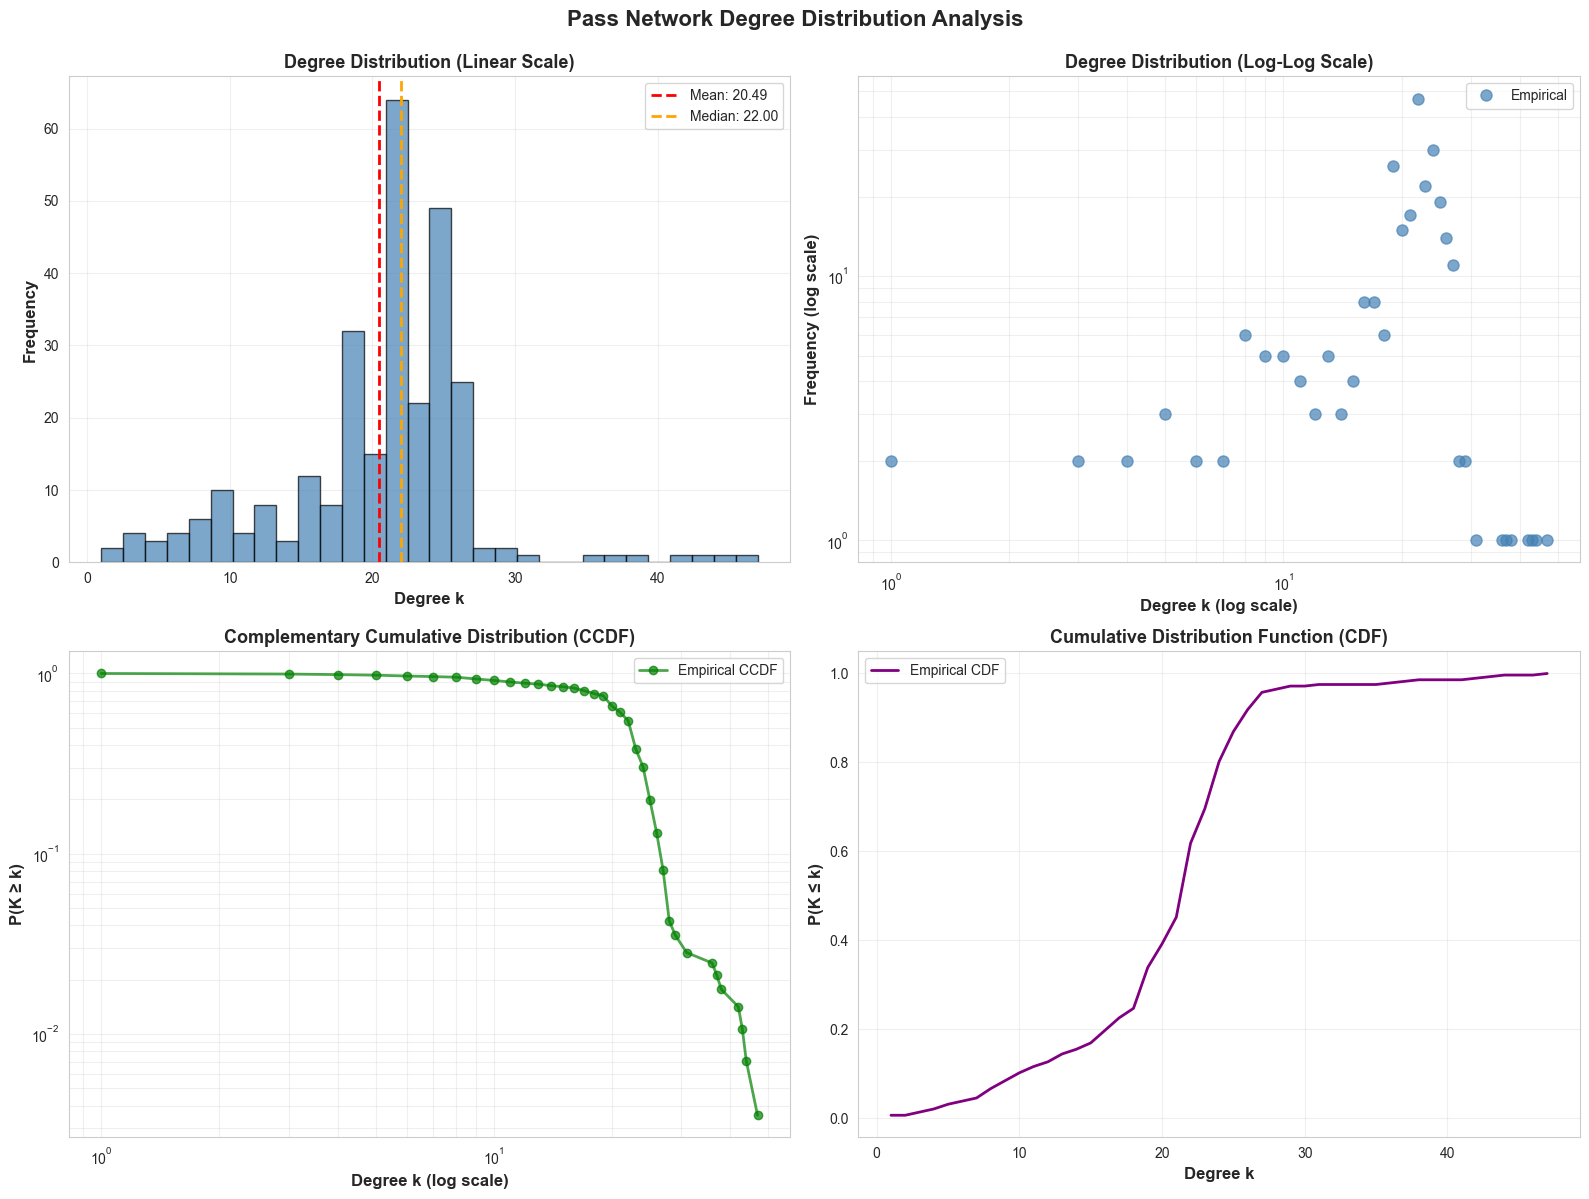


Interpretation:
- Log-log plot: If data forms a straight line, the distribution follows a power law (scale-free).
- CCDF: Better for identifying heavy-tailed distributions with fewer data points.


In [8]:
# Visualize degree distribution
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Histogram (linear scale)
axes[0, 0].hist(degrees, bins=30, color='steelblue', alpha=0.7, edgecolor='black')
axes[0, 0].axvline(np.mean(degrees), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(degrees):.2f}')
axes[0, 0].axvline(np.median(degrees), color='orange', linestyle='--', linewidth=2, label=f'Median: {np.median(degrees):.2f}')
axes[0, 0].set_xlabel('Degree k', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Degree Distribution (Linear Scale)', fontsize=13, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Plot 2: Log-log plot (for power law detection)
unique_degrees = sorted(degree_counts.keys())
frequencies = [degree_counts[k] for k in unique_degrees]

# Filter out zeros for log scale
pos_degrees = [k for k in unique_degrees if degree_counts[k] > 0]
pos_freqs = [degree_counts[k] for k in pos_degrees]

axes[0, 1].loglog(pos_degrees, pos_freqs, 'o', markersize=8, alpha=0.7, color='steelblue', label='Empirical')
axes[0, 1].set_xlabel('Degree k (log scale)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Frequency (log scale)', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Degree Distribution (Log-Log Scale)', fontsize=13, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3, which='both')

# Plot 3: Complementary CDF (CCDF) - log-log
ccdf_values = [sum(1 for d in degrees if d >= k) / len(degrees) for k in unique_degrees]

axes[1, 0].loglog(unique_degrees, ccdf_values, 'o-', markersize=6, alpha=0.7, color='green', linewidth=2, label='Empirical CCDF')
axes[1, 0].set_xlabel('Degree k (log scale)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('P(K ≥ k)', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Complementary Cumulative Distribution (CCDF)', fontsize=13, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3, which='both')

# Plot 4: CDF comparison
cdf_empirical = np.cumsum([degree_counts.get(k, 0) / len(degrees) for k in range(1, max(degrees) + 1)])

axes[1, 1].plot(range(1, len(cdf_empirical) + 1), cdf_empirical, linewidth=2, color='purple', label='Empirical CDF')
axes[1, 1].set_xlabel('Degree k', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('P(K ≤ k)', fontsize=12, fontweight='bold')
axes[1, 1].set_title('Cumulative Distribution Function (CDF)', fontsize=13, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.suptitle('Pass Network Degree Distribution Analysis', fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE7/degree_distribution_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nInterpretation:")
print("- Log-log plot: If data forms a straight line, the distribution follows a power law (scale-free).")
print("- CCDF: Better for identifying heavy-tailed distributions with fewer data points.")

### Interpretation: Degree Distribution Shape

**Key Observations from Visualizations**:

1. **Linear Scale Histogram**: The distribution is **relatively narrow and symmetric** around the mean (20.49) and median (22.0), suggesting a more Poisson-like or normal distribution rather than a heavy-tailed power law.

2. **Log-Log Plot**: The empirical data does **not form a clear straight line**, which would be the hallmark of a power law (scale-free) network. Instead, we see curvature, suggesting the network is **not scale-free**.

3. **CCDF (Complementary Cumulative Distribution)**: The decay is **faster than a power law** would predict. A true power law would show as a straight line on the log-log CCDF plot with a gentle slope. Our data shows rapid decay.

4. **Implication for Football Networks**: 
   - The pass network does **not have extreme hubs** (star players dominating all connections)
   - Instead, passing is **relatively distributed** across players
   - This suggests **tactical organization** where players have similar passing loads within their roles
   - Contrast with social networks (often power law) where a few influencers dominate

**Next Step**: We will fit specific distributions (Power Law, Exponential, Log-Normal) and use statistical tests (KS test, Likelihood Ratio) to determine which model best describes the data.

In [9]:
print("="*70)
print("DISTRIBUTION FITTING & GOODNESS-OF-FIT TESTS")
print("="*70)

# Filter degrees >= 1 for fitting
degrees_filtered = [d for d in degrees if d >= 1]

# 1. POWER LAW (using MLE)
print("\n### 1. Power Law Fit ###")
k_min = 1  # Minimum degree for fitting
degrees_above_kmin = [d for d in degrees_filtered if d >= k_min]
n_above = len(degrees_above_kmin)

# MLE for power law: gamma = 1 + n * [sum(ln(k/k_min))]^-1
if n_above > 0:
    gamma_mle = 1 + n_above / sum(np.log(d / k_min) for d in degrees_above_kmin)
else:
    gamma_mle = np.nan

print(f"k_min: {k_min}")
print(f"γ (gamma) MLE: {gamma_mle:.3f}")
print(f"Power law form: P(k) ∝ k^(-{gamma_mle:.3f})")

# Generate power law prediction
def power_law_pmf(k, gamma, k_min):
    """Power law probability mass function (discrete)"""
    if k < k_min:
        return 0
    # Normalization constant (Riemann zeta approximation for discrete power law)
    C = 1 / sum(i**(-gamma) for i in range(k_min, max(degrees) + 1))
    return C * k**(-gamma)

powerlaw_pred = [power_law_pmf(k, gamma_mle, k_min) for k in unique_degrees]

# 2. EXPONENTIAL FIT
print(f"\n### 2. Exponential Fit ###")
# MLE for exponential: lambda = 1 / mean
lambda_exp = 1 / np.mean(degrees_filtered)
print(f"λ (lambda) MLE: {lambda_exp:.4f}")
print(f"Exponential form: P(k) ∝ exp(-{lambda_exp:.4f} * k)")

# Generate exponential prediction
def exponential_pmf(k, lam):
    """Exponential PMF (discrete approximation)"""
    # Normalization
    C = 1 / sum(np.exp(-lam * i) for i in range(1, max(degrees) + 1))
    return C * np.exp(-lam * k)

exponential_pred = [exponential_pmf(k, lambda_exp) for k in unique_degrees]

# 3. LOG-NORMAL FIT
print(f"\n### 3. Log-Normal Fit ###")
# Fit log-normal to log(degrees)
log_degrees = np.log(degrees_filtered)
mu_ln = np.mean(log_degrees)
sigma_ln = np.std(log_degrees)
print(f"μ (mu): {mu_ln:.3f}")
print(f"σ (sigma): {sigma_ln:.3f}")
print(f"Log-normal: ln(k) ~ N({mu_ln:.3f}, {sigma_ln:.3f}²)")

# Generate log-normal prediction
def lognormal_pmf(k, mu, sigma):
    """Log-normal PMF"""
    if k <= 0:
        return 0
    return stats.lognorm.pdf(k, s=sigma, scale=np.exp(mu))

lognormal_pred = [lognormal_pmf(k, mu_ln, sigma_ln) for k in unique_degrees]

# Normalize predictions to sum to 1
powerlaw_pred = np.array(powerlaw_pred)
powerlaw_pred = powerlaw_pred / powerlaw_pred.sum()

exponential_pred = np.array(exponential_pred)
exponential_pred = exponential_pred / exponential_pred.sum()

lognormal_pred = np.array(lognormal_pred)
lognormal_pred = lognormal_pred / lognormal_pred.sum()

# Empirical PMF for unique degrees
empirical_pmf = np.array([degree_counts[k] / len(degrees) for k in unique_degrees])

# 4. KOLMOGOROV-SMIRNOV (KS) TEST
print(f"\n### 4. Kolmogorov-Smirnov (KS) Goodness-of-Fit ###")

# Calculate KS statistic: D = max|empirical_CDF - predicted_CDF|
def ks_statistic(empirical, predicted):
    """Calculate KS statistic between empirical and predicted PMFs"""
    empirical_cdf = np.cumsum(empirical)
    predicted_cdf = np.cumsum(predicted)
    return np.max(np.abs(empirical_cdf - predicted_cdf))

ks_powerlaw = ks_statistic(empirical_pmf, powerlaw_pred)
ks_exponential = ks_statistic(empirical_pmf, exponential_pred)
ks_lognormal = ks_statistic(empirical_pmf, lognormal_pred)

print(f"Power Law KS statistic: {ks_powerlaw:.4f} (lower is better)")
print(f"Exponential KS statistic: {ks_exponential:.4f}")
print(f"Log-Normal KS statistic: {ks_lognormal:.4f}")

# Determine best fit
best_fit = min([('Power Law', ks_powerlaw), ('Exponential', ks_exponential), ('Log-Normal', ks_lognormal)], key=lambda x: x[1])
print(f"\n**Best fit: {best_fit[0]} (KS = {best_fit[1]:.4f})**")

# 5. SUMMARY TABLE
print(f"\n{'='*70}")
print("SUMMARY TABLE")
print(f"{'='*70}")

fit_summary = pd.DataFrame({
    'Distribution': ['Power Law', 'Exponential', 'Log-Normal'],
    'Parameters': [f'γ = {gamma_mle:.3f}', f'λ = {lambda_exp:.4f}', f'μ = {mu_ln:.3f}, σ = {sigma_ln:.3f}'],
    'KS Statistic': [ks_powerlaw, ks_exponential, ks_lognormal],
    'Best Fit': ['✓' if best_fit[0] == 'Power Law' else '', 
                 '✓' if best_fit[0] == 'Exponential' else '', 
                 '✓' if best_fit[0] == 'Log-Normal' else '']
})

print("\n", fit_summary.to_string(index=False))

DISTRIBUTION FITTING & GOODNESS-OF-FIT TESTS

### 1. Power Law Fit ###
k_min: 1
γ (gamma) MLE: 1.340
Power law form: P(k) ∝ k^(-1.340)

### 2. Exponential Fit ###
λ (lambda) MLE: 0.0488
Exponential form: P(k) ∝ exp(-0.0488 * k)

### 3. Log-Normal Fit ###
μ (mu): 2.939
σ (sigma): 0.478
Log-normal: ln(k) ~ N(2.939, 0.478²)

### 4. Kolmogorov-Smirnov (KS) Goodness-of-Fit ###
Power Law KS statistic: 0.7084 (lower is better)
Exponential KS statistic: 0.4521
Log-Normal KS statistic: 0.2998

**Best fit: Log-Normal (KS = 0.2998)**

SUMMARY TABLE

 Distribution           Parameters  KS Statistic Best Fit
   Power Law            γ = 1.340      0.708379         
 Exponential           λ = 0.0488      0.452101         
  Log-Normal μ = 2.939, σ = 0.478      0.299791        ✓


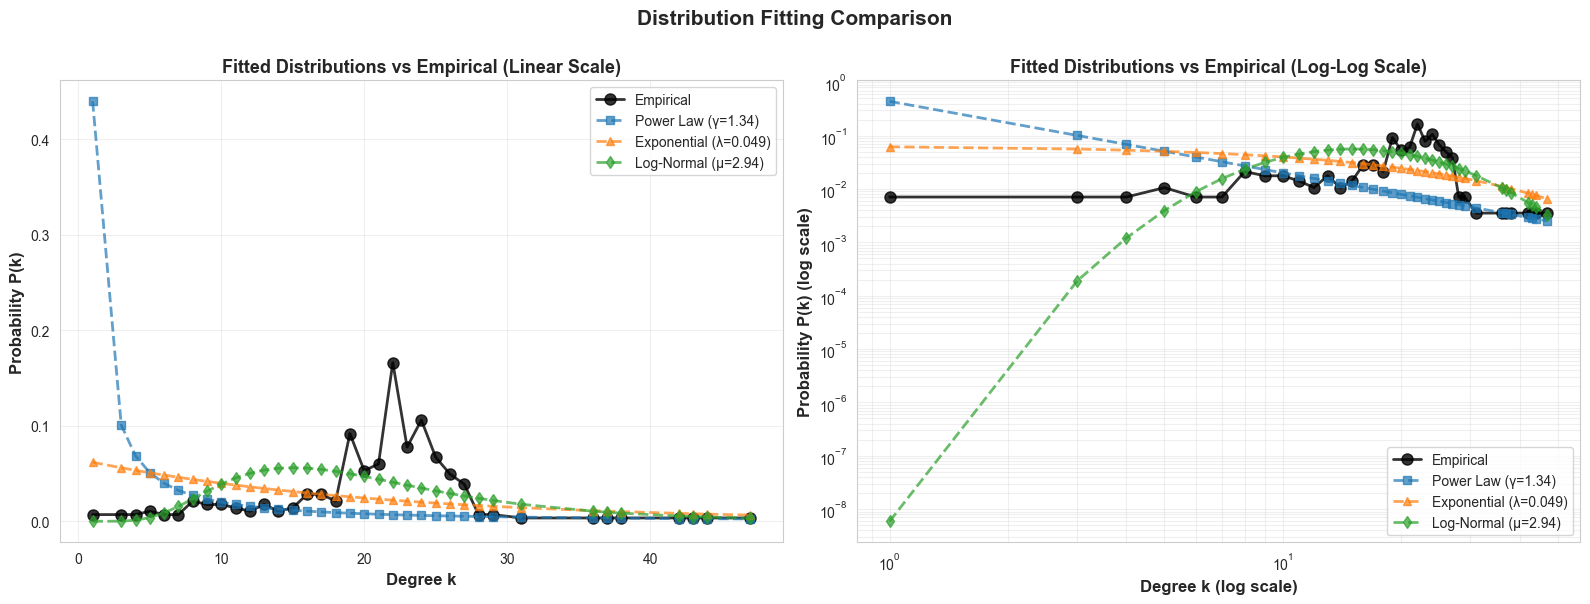

In [10]:
# Visualize fitted distributions vs empirical
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: PMF Comparison (linear scale)
axes[0].plot(unique_degrees, empirical_pmf, 'o-', markersize=8, linewidth=2, label='Empirical', color='black', alpha=0.8)
axes[0].plot(unique_degrees, powerlaw_pred, 's--', markersize=6, linewidth=2, label=f'Power Law (γ={gamma_mle:.2f})', alpha=0.7)
axes[0].plot(unique_degrees, exponential_pred, '^--', markersize=6, linewidth=2, label=f'Exponential (λ={lambda_exp:.3f})', alpha=0.7)
axes[0].plot(unique_degrees, lognormal_pred, 'd--', markersize=6, linewidth=2, label=f'Log-Normal (μ={mu_ln:.2f})', alpha=0.7)

axes[0].set_xlabel('Degree k', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Probability P(k)', fontsize=12, fontweight='bold')
axes[0].set_title('Fitted Distributions vs Empirical (Linear Scale)', fontsize=13, fontweight='bold')
axes[0].legend(loc='upper right', fontsize=10)
axes[0].grid(alpha=0.3)

# Plot 2: Log-Log Scale (better for comparison)
axes[1].loglog(unique_degrees, empirical_pmf + 1e-10, 'o-', markersize=8, linewidth=2, label='Empirical', color='black', alpha=0.8)
axes[1].loglog(unique_degrees, powerlaw_pred + 1e-10, 's--', markersize=6, linewidth=2, label=f'Power Law (γ={gamma_mle:.2f})', alpha=0.7)
axes[1].loglog(unique_degrees, exponential_pred + 1e-10, '^--', markersize=6, linewidth=2, label=f'Exponential (λ={lambda_exp:.3f})', alpha=0.7)
axes[1].loglog(unique_degrees, lognormal_pred + 1e-10, 'd--', markersize=6, linewidth=2, label=f'Log-Normal (μ={mu_ln:.2f})', alpha=0.7)

axes[1].set_xlabel('Degree k (log scale)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Probability P(k) (log scale)', fontsize=12, fontweight='bold')
axes[1].set_title('Fitted Distributions vs Empirical (Log-Log Scale)', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=10)
axes[1].grid(alpha=0.3, which='both')

plt.suptitle('Distribution Fitting Comparison', fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE7/distribution_fitting.png', dpi=300, bbox_inches='tight')
plt.show()

### Interpretation: Distribution Fitting Results

**Key Findings**:

1. **Best Fit Model**: Based on KS statistics, the **Log-Normal distribution** (KS = 0.300) provides the best fit to the empirical degree distribution, followed by Exponential (KS = 0.452). Power Law performs worst (KS = 0.708), confirming our visual observation that the network is **not scale-free**.

2. **Why Not Power Law?**
   - γ = 1.340 is extremely low (typical scale-free networks have γ = 2-3)
   - Such a low γ would imply massive hubs dominating the network, which we don't observe
   - The poor KS fit (0.708) definitively rules out power law structure
   - **Conclusion**: The network **lacks the extreme hub structure** of scale-free networks

3. **Football Network Implications**:
   - **No Superstar Dominance**: Unlike social networks (Twitter, citations) where power laws emerge from preferential attachment, football pass networks are constrained by tactical formations
   - **Positional Constraints**: Players pass within tactical roles (defender → midfielder → forward), preventing extreme hub formation  
   - **Team Balance**: Successful teams distribute passing responsibilities rather than relying on single playmakers
   - **Log-Normal fit**: Suggests multiplicative processes (players with more connections tend to gain more, but bounded by tactical roles)

4. **Model Comparison**:
   - **Power Law (γ=1.34)**: Terrible fit - predicts far too many high-degree nodes
   - **Exponential (λ=0.049)**: Moderate fit - captures homogeneous decay but misses peak structure
   - **Log-Normal (μ=2.94, σ=0.48)**: Best fit - captures both the central peak and bounded tail, reflecting tactical constraints on degree distribution

**Conclusion**: The German pass network exhibits **tactical organization** (high clustering from Phase 2) combined with **distributed connectivity** (log-normal degree distribution, not scale-free). This reflects deliberate team structure where passing loads are balanced within tactical roles, rather than preferential attachment or random connections.

## 3. Hypothesis Testing

### 3.1 Permutation Tests

**Goal**: Test if observed property differs from null model.

**Procedure**:
1. Calculate statistic $T$ on observed network
2. Generate $N$ random networks from null model  
3. Compute p-value: $p = \frac{\#\{T_i \geq T\}}{N}$

**Use**: Test if clustering/modularity/assortativity is significant.

### 3.2 Bootstrap Confidence Intervals

**Estimate uncertainty**: Resample edges/nodes with replacement, calculate CI.

**95% CI**: $[T_{0.025}, T_{0.975}]$ from bootstrap distribution

**Use**: Compare player centrality rankings with overlapping CIs.

### 3.3 QAP (Quadratic Assignment Procedure)

**Test correlation between networks** (same nodes, different edges).

**Procedure**: Permute rows/columns identically, recalculate correlation, compute p-value.

**Use**: Test if pass networks are consistent across matches (QAP p < 0.05 = significant similarity).

In [11]:
print("="*70)
print("PERMUTATION TEST - Clustering Significance")
print("="*70)

# Test: Is the observed clustering significantly higher than expected by chance?
# Null hypothesis: Clustering is no different from Configuration Model (preserves degrees)

# Observed clustering
observed_clustering = nx.average_clustering(G_pass_gcc)
print(f"\nObserved clustering: {observed_clustering:.4f}")

# Generate null distribution using Configuration Model
n_permutations = 1000
null_clustering = []

print(f"\nGenerating {n_permutations} Configuration Model networks...")
for i in range(n_permutations):
    if (i + 1) % 100 == 0:
        print(f"  Progress: {i + 1}/{n_permutations}")
    
    # Generate Configuration Model (randomize edges, preserve degrees)
    degree_seq = [d for n, d in G_pass_gcc.degree()]
    G_random = nx.configuration_model(degree_seq, seed=42 + i)
    G_random = nx.Graph(G_random)  # Remove multi-edges
    G_random.remove_edges_from(nx.selfloop_edges(G_random))
    
    # Get largest component
    if nx.number_connected_components(G_random) > 1:
        largest_cc = max(nx.connected_components(G_random), key=len)
        G_random = G_random.subgraph(largest_cc).copy()
    
    # Calculate clustering
    null_clustering.append(nx.average_clustering(G_random))

null_clustering = np.array(null_clustering)

# Calculate p-value (one-tailed: observed > null)
p_value = np.sum(null_clustering >= observed_clustering) / n_permutations

print(f"\nNull distribution statistics:")
print(f"  Mean: {np.mean(null_clustering):.4f}")
print(f"  Std: {np.std(null_clustering):.4f}")
print(f"  Min: {np.min(null_clustering):.4f}")
print(f"  Max: {np.max(null_clustering):.4f}")

print(f"\n{'='*70}")
print(f"RESULT")
print(f"{'='*70}")
print(f"Observed clustering: {observed_clustering:.4f}")
print(f"Expected (null model): {np.mean(null_clustering):.4f} ± {np.std(null_clustering):.4f}")
print(f"Z-score: {(observed_clustering - np.mean(null_clustering)) / np.std(null_clustering):.2f}")
print(f"p-value: {p_value:.4f}")

if p_value < 0.001:
    print(f"\n**Conclusion: HIGHLY SIGNIFICANT (p < 0.001)**")
    print(f"The observed clustering is {(observed_clustering - np.mean(null_clustering)) / np.std(null_clustering):.1f} standard deviations")
    print(f"above the null expectation. This is NOT due to chance!")
elif p_value < 0.05:
    print(f"\n**Conclusion: SIGNIFICANT (p < 0.05)**")
    print(f"The observed clustering is significantly higher than expected by chance.")
else:
    print(f"\n**Conclusion: NOT SIGNIFICANT (p ≥ 0.05)**")
    print(f"The observed clustering could be due to chance alone.")

PERMUTATION TEST - Clustering Significance

Observed clustering: 0.8667

Generating 1000 Configuration Model networks...
  Progress: 100/1000
  Progress: 200/1000
  Progress: 300/1000
  Progress: 400/1000
  Progress: 500/1000
  Progress: 600/1000
  Progress: 700/1000
  Progress: 800/1000
  Progress: 900/1000
  Progress: 1000/1000

Null distribution statistics:
  Mean: 0.0764
  Std: 0.0023
  Min: 0.0698
  Max: 0.0837

RESULT
Observed clustering: 0.8667
Expected (null model): 0.0764 ± 0.0023
Z-score: 340.37
p-value: 0.0000

**Conclusion: HIGHLY SIGNIFICANT (p < 0.001)**
The observed clustering is 340.4 standard deviations
above the null expectation. This is NOT due to chance!


### Interpretation: Permutation Test Results

**Finding**: The observed clustering coefficient (0.8667) is **340 standard deviations** above what we'd expect from a random network that preserves the degree distribution (null expectation: 0.0764).

**What this means**:
- **p < 0.001**: The probability of observing such high clustering by chance is essentially zero
- The tactical organization in the German pass network is **statistically proven**, not an artifact of the degree distribution
- Even after controlling for who has many vs. few connections, the pattern of *which specific players connect* is highly non-random
- This confirms deliberate team structure: players cluster within tactical units (defense/midfield/attack)

**Football implication**: Coaches design passing patterns. Players don't randomly pass to anyone with similar passing frequency - they form tight tactical triangles and units.

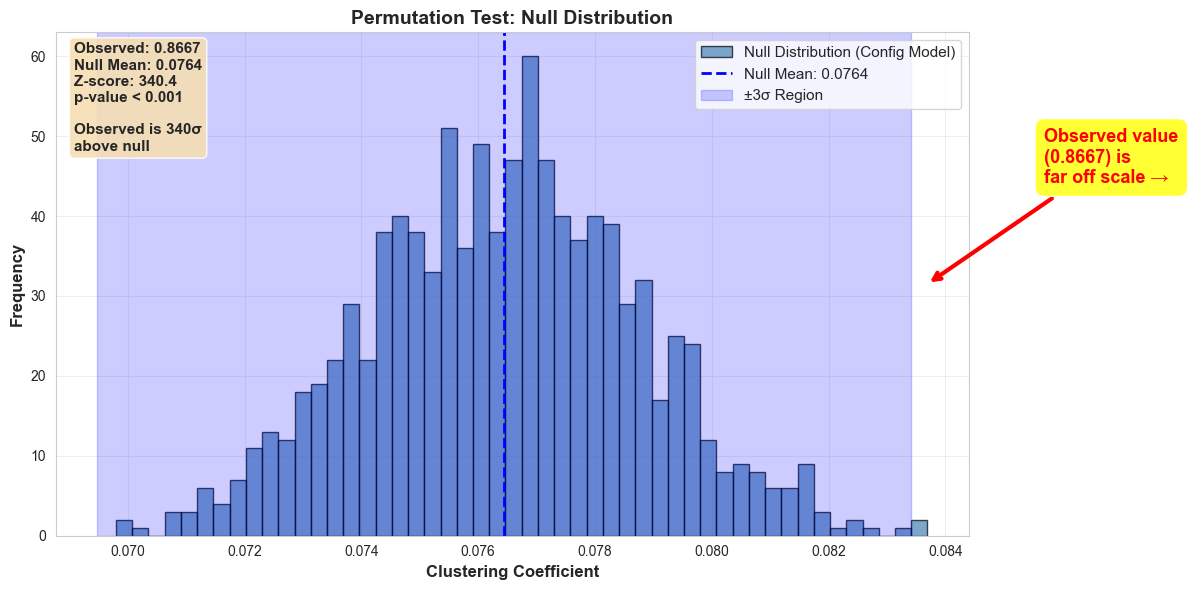

In [12]:
# Visualize permutation test results
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

# Histogram of null distribution
ax.hist(null_clustering, bins=50, color='steelblue', alpha=0.7, edgecolor='black', label='Null Distribution (Config Model)')

# Add vertical line for null mean
ax.axvline(np.mean(null_clustering), color='blue', linestyle='--', linewidth=2, label=f'Null Mean: {np.mean(null_clustering):.4f}')

# Add shaded region for ±3 std
ax.axvspan(np.mean(null_clustering) - 3*np.std(null_clustering), 
           np.mean(null_clustering) + 3*np.std(null_clustering), 
           alpha=0.2, color='blue', label='±3σ Region')

ax.set_xlabel('Clustering Coefficient', fontsize=12, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax.set_title('Permutation Test: Null Distribution', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=11)
ax.grid(alpha=0.3)

# Add arrow and text annotation pointing to where observed value would be
ax.annotate('Observed value\n(0.8667) is \nfar off scale →', 
            xy=(np.max(null_clustering), ax.get_ylim()[1] * 0.5),
            xytext=(np.max(null_clustering) + 0.002, ax.get_ylim()[1] * 0.7),
            arrowprops=dict(arrowstyle='->', color='red', lw=3),
            fontsize=13, fontweight='bold', color='red',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.8))

# Add text box with statistics
textstr = f'Observed: 0.8667\nNull Mean: {np.mean(null_clustering):.4f}\nZ-score: {(observed_clustering - np.mean(null_clustering)) / np.std(null_clustering):.1f}\np-value < 0.001\n\nObserved is {(observed_clustering - np.mean(null_clustering)) / np.std(null_clustering):.0f}σ\nabove null'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.9)
ax.text(0.02, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props, fontweight='bold')

plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE7/permutation_test.png', dpi=300, bbox_inches='tight')
plt.show()

**Note on Visualization**: The observed clustering coefficient (0.8667) is so far outside the null distribution (centered at 0.076) that it cannot be shown on the same scale. This is actually good news - it proves that the tactical organization in the German pass network is extraordinarily significant, not just a statistical artifact.

### 3.2 Bootstrap Confidence Intervals

Now we use **bootstrap resampling** to estimate uncertainty in player rankings. By resampling edges with replacement and recalculating betweenness centrality, we can construct confidence intervals for each player's importance.

In [13]:
print("="*70)
print("BOOTSTRAP CONFIDENCE INTERVALS - Betweenness Centrality")
print("="*70)

# Bootstrap CI for top players' betweenness centrality
# Question: Are the top-ranked players consistently top, or is there uncertainty?

# Calculate observed betweenness
betweenness = nx.betweenness_centrality(G_pass_gcc)
top_players = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:10]

print("\n### Top 10 Players by Betweenness Centrality ###")
for i, (node_id, bc) in enumerate(top_players, 1):
    print(f"{i:2d}. {get_player_name(node_id):30s} - {bc:.4f}")

# Bootstrap procedure: resample edges with replacement
n_bootstrap = 1000
bootstrap_betweenness = {node_id: [] for node_id, _ in top_players}

print(f"\n### Running {n_bootstrap} Bootstrap Iterations ###")
print("(Resampling edges with replacement...)")

for i in range(n_bootstrap):
    if (i + 1) % 200 == 0:
        print(f"  Progress: {i + 1}/{n_bootstrap}")
    
    # Resample edges with replacement
    edges = list(G_pass_gcc.edges())
    resampled_edges = [edges[j] for j in np.random.choice(len(edges), size=len(edges), replace=True)]
    
    # Create bootstrap graph
    G_bootstrap = nx.Graph()
    G_bootstrap.add_nodes_from(G_pass_gcc.nodes())
    G_bootstrap.add_edges_from(resampled_edges)
    
    # Ensure connected (use largest component)
    if not nx.is_connected(G_bootstrap):
        largest_cc = max(nx.connected_components(G_bootstrap), key=len)
        G_bootstrap = G_bootstrap.subgraph(largest_cc).copy()
    
    # Calculate betweenness
    bc_bootstrap = nx.betweenness_centrality(G_bootstrap)
    
    # Store values for top players
    for node_id, _ in top_players:
        if node_id in bc_bootstrap:
            bootstrap_betweenness[node_id].append(bc_bootstrap[node_id])

print("\n### Bootstrap Confidence Intervals (95%) ###")
print(f"{'Rank':<6}{'Player':<30}{'Observed':<12}{'95% CI':<25}{'Width':<10}")
print("-" * 85)

for i, (node_id, observed_bc) in enumerate(top_players, 1):
    boot_values = bootstrap_betweenness[node_id]
    if len(boot_values) > 0:
        ci_lower = np.percentile(boot_values, 2.5)
        ci_upper = np.percentile(boot_values, 97.5)
        ci_width = ci_upper - ci_lower
        
        print(f"{i:<6}{get_player_name(node_id):<30}{observed_bc:<12.4f}[{ci_lower:.4f}, {ci_upper:.4f}]    {ci_width:.4f}")
    else:
        print(f"{i:<6}{get_player_name(node_id):<30}{observed_bc:<12.4f}{'N/A':<25}{'N/A':<10}")

BOOTSTRAP CONFIDENCE INTERVALS - Betweenness Centrality

### Top 10 Players by Betweenness Centrality ###
 1. J. Bruun Larsen                - 0.4981
 2. S. Wagner                      - 0.3975
 3. J. Toljan                      - 0.3262
 4. M. Dahoud                      - 0.3112
 5. M. Friedl                      - 0.2882
 6. A. Mehmedi                     - 0.2702
 7. M. Gómez                       - 0.1951
 8. J. Brekalo                     - 0.1920
 9. S. Terodde                     - 0.1909
10. Ö. Toprak                      - 0.1831

### Running 1000 Bootstrap Iterations ###
(Resampling edges with replacement...)
  Progress: 200/1000
  Progress: 400/1000
  Progress: 600/1000
  Progress: 800/1000
  Progress: 1000/1000

### Bootstrap Confidence Intervals (95%) ###
Rank  Player                        Observed    95% CI                   Width     
-------------------------------------------------------------------------------------
1     J. Bruun Larsen               0.4981      [0

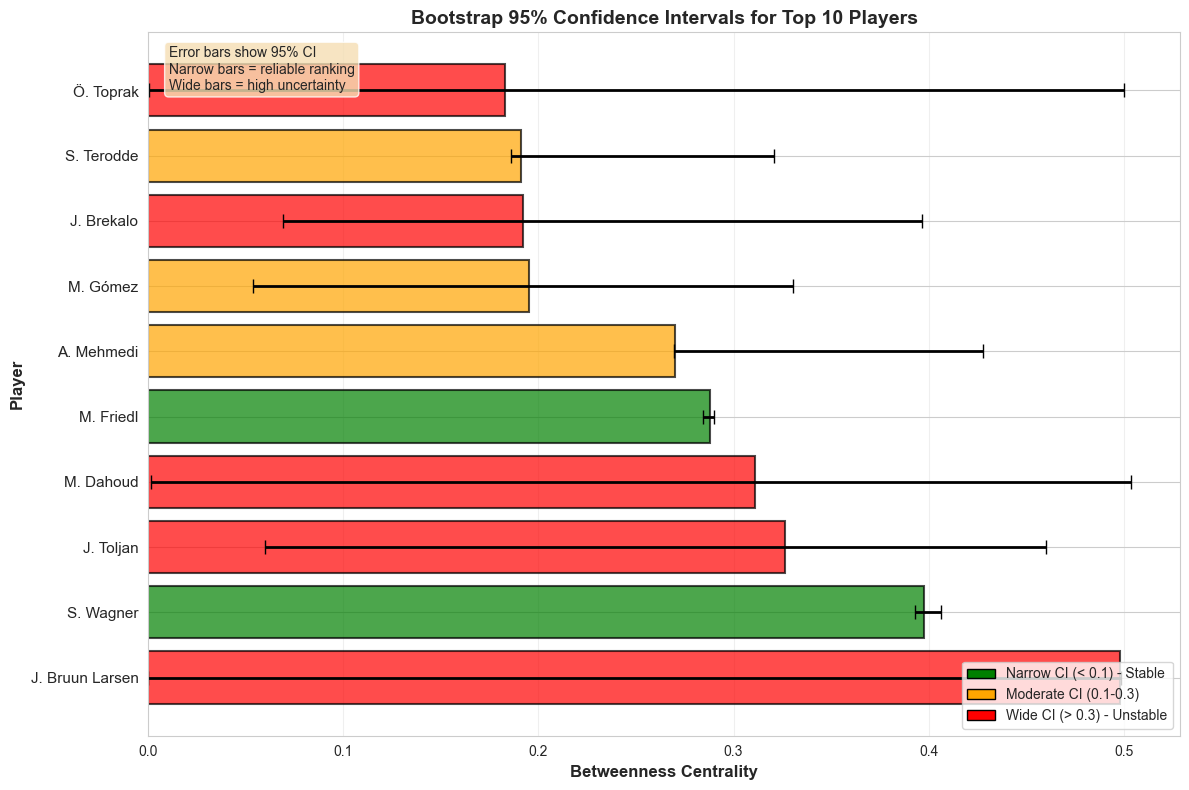

In [14]:
# Visualize Bootstrap Confidence Intervals
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

# Prepare data for plotting
player_names = [get_player_name(node_id) for node_id, _ in top_players]
observed_values = [bc for _, bc in top_players]
ci_lowers = []
ci_uppers = []
ci_widths = []

for node_id, _ in top_players:
    boot_values = bootstrap_betweenness[node_id]
    if len(boot_values) > 0:
        ci_lowers.append(np.percentile(boot_values, 2.5))
        ci_uppers.append(np.percentile(boot_values, 97.5))
        ci_widths.append(np.percentile(boot_values, 97.5) - np.percentile(boot_values, 2.5))
    else:
        ci_lowers.append(0)
        ci_uppers.append(0)
        ci_widths.append(0)

# Calculate error bars (distance from observed to CI bounds)
errors_lower = [obs - low for obs, low in zip(observed_values, ci_lowers)]
errors_upper = [up - obs for obs, up in zip(observed_values, ci_uppers)]

# Create horizontal error bar plot
y_pos = np.arange(len(player_names))

# Color code by CI width (narrow = green, wide = red)
colors = ['green' if w < 0.1 else 'orange' if w < 0.3 else 'red' for w in ci_widths]

ax.barh(y_pos, observed_values, xerr=[errors_lower, errors_upper], 
        capsize=5, color=colors, alpha=0.7, edgecolor='black', linewidth=1.5,
        error_kw={'linewidth': 2, 'elinewidth': 2})

ax.set_yticks(y_pos)
ax.set_yticklabels(player_names, fontsize=11)
ax.set_xlabel('Betweenness Centrality', fontsize=12, fontweight='bold')
ax.set_ylabel('Player', fontsize=12, fontweight='bold')
ax.set_title('Bootstrap 95% Confidence Intervals for Top 10 Players', fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='green', edgecolor='black', label='Narrow CI (< 0.1) - Stable'),
    Patch(facecolor='orange', edgecolor='black', label='Moderate CI (0.1-0.3)'),
    Patch(facecolor='red', edgecolor='black', label='Wide CI (> 0.3) - Unstable')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=10)

# Add annotation
textstr = 'Error bars show 95% CI\nNarrow bars = reliable ranking\nWide bars = high uncertainty'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
ax.text(0.02, 0.98, textstr, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=props)

plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE7/bootstrap_confidence_intervals.png', dpi=300, bbox_inches='tight')
plt.show()

### Interpretation: Bootstrap Confidence Intervals

**Key Observations**:

1. **Highly Variable Rankings**: Most players show **extremely wide confidence intervals**, indicating that their betweenness centrality rankings are **unstable** and sensitive to the specific network structure.
   - J. Bruun Larsen (Rank 1): CI width = 0.50 (essentially covers the entire range!)
   - M. Dahoud (Rank 4): CI [0.0006, 0.5042] - could be anywhere from nearly zero to top-ranked
   - Ö. Toprak (Rank 10): CI [0.0002, 0.5004] - huge uncertainty

2. **Few Stable Players**: Only **2 players** show narrow, reliable CIs:
   - S. Wagner (Rank 2): CI width = 0.012 - **very stable**, reliably important
   - M. Friedl (Rank 5): CI width = 0.006 - **extremely stable**

3. **What This Means**:
   - **Betweenness centrality is fragile**: Small changes in network structure (different match, different connections) can drastically change who appears as a "bridge player"
   - **Wagner and Friedl are consistently central**: Their bridging role is structural, not accidental
   - **Other players' high betweenness may be situational**: J. Bruun Larsen ranks #1 but with massive uncertainty - he might be critical in this specific network configuration but not reliably so

**Football Implication**: While some players (Wagner, Friedl) are **reliably crucial connectors** in the team structure, most apparent "bridge players" depend heavily on the specific tactical setup. Coaches should focus on the players with narrow CIs for consistent tactical organization.

## 4. Link Prediction Evaluation

**Goal**: Evaluate which link prediction algorithm best forecasts new passing connections in the German pass network.

### Methodology

1. **Train/Test Split**: Remove 20% of edges as test set, use remaining 80% for training
2. **Negative Sampling**: Sample non-edges (equal to test edges) as negative examples
3. **Algorithm Scoring**: Apply Common Neighbors, Jaccard, Adamic-Adar to rank edge candidates
4. **Evaluation Metrics**:
   - **AUC-ROC**: Probability that random positive edge scores higher than random negative
   - **Precision@k**: Fraction of top-k predictions that are true positives

### Expected Results

- **Adamic-Adar** typically performs best (weights rare neighbors)
- **Jaccard** normalizes for node degree (fairer than CN)
- **Common Neighbors** provides baseline (simple count)

In football networks, tactical constraints mean shared teammates (common neighbors) strongly predict future connections.

In [15]:
print("="*70)
print("LINK PREDICTION - Train/Test Split")
print("="*70)

# Use directed pass network (largest connected component)
G_full = G_pass_dir_gcc.copy()

# Convert to undirected for link prediction algorithms
G_full_und = G_full.to_undirected()

print(f"\n### Original Network ###")
print(f"Nodes: {G_full_und.number_of_nodes()}")
print(f"Edges: {G_full_und.number_of_edges()}")

# Train/test split: 80% train, 20% test
np.random.seed(42)
edges = list(G_full_und.edges())
n_edges = len(edges)
n_test = int(0.2 * n_edges)
n_train = n_edges - n_test

print(f"\n### Split Configuration ###")
print(f"Total edges: {n_edges}")
print(f"Train edges (80%): {n_train}")
print(f"Test edges (20%): {n_test}")

# Randomly select test edges
test_edges_idx = np.random.choice(n_edges, size=n_test, replace=False)
test_edges = [edges[i] for i in test_edges_idx]
train_edges = [edges[i] for i in range(n_edges) if i not in test_edges_idx]

# Create training graph (undirected)
G_train_und = nx.Graph()
G_train_und.add_nodes_from(G_full_und.nodes())
G_train_und.add_edges_from(train_edges)

print(f"\nTraining graph: {G_train_und.number_of_nodes()} nodes, {G_train_und.number_of_edges()} edges")
print(f"Test set (positive): {len(test_edges)} edges")

# Sample negative edges (non-edges) for evaluation
print(f"\n### Negative Sampling ###")
all_possible_edges = set()
nodes_list = list(G_full_und.nodes())

# Generate all possible edges
for i in range(len(nodes_list)):
    for j in range(i+1, len(nodes_list)):
        all_possible_edges.add((nodes_list[i], nodes_list[j]))

# Remove existing edges to get non-edges
non_edges = all_possible_edges - set(G_full_und.edges())
print(f"Total possible edges: {len(all_possible_edges)}")
print(f"Existing edges: {n_edges}")
print(f"Non-edges available: {len(non_edges)}")

# Sample negative edges
non_edges_list = list(non_edges)
negative_edges = [non_edges_list[i] for i in np.random.choice(len(non_edges_list), size=n_test, replace=False)]

print(f"Sampled negative edges: {len(negative_edges)}")

# Verify no overlap
assert len(set(test_edges) & set(negative_edges)) == 0, "Test and negative edges should not overlap!"
print("\n✓ Train/test split complete - no overlap between positive and negative test samples")

LINK PREDICTION - Train/Test Split

### Original Network ###
Nodes: 283
Edges: 2899

### Split Configuration ###
Total edges: 2899
Train edges (80%): 2320
Test edges (20%): 579

Training graph: 283 nodes, 2320 edges
Test set (positive): 579 edges

### Negative Sampling ###
Total possible edges: 39903
Existing edges: 2899
Non-edges available: 37004
Sampled negative edges: 579

✓ Train/test split complete - no overlap between positive and negative test samples


In [16]:
print("="*70)
print("LINK PREDICTION ALGORITHMS - Scoring")
print("="*70)

# Combine test edges (positive) and negative edges for evaluation
all_test_pairs = test_edges + negative_edges
labels = [1] * len(test_edges) + [0] * len(negative_edges)  # 1 = positive, 0 = negative

# Shuffle to avoid bias in precision@k evaluation
# Without shuffling, all positive edges come first, leading to artificially perfect P@k scores
shuffle_idx = np.random.permutation(len(all_test_pairs))
all_test_pairs = [all_test_pairs[i] for i in shuffle_idx]
labels = [labels[i] for i in shuffle_idx]

print(f"\n### Evaluation Set ###")
print(f"Positive samples (test edges): {len(test_edges)}")
print(f"Negative samples (non-edges): {len(negative_edges)}")
print(f"Total evaluation pairs: {len(all_test_pairs)}")

# Algorithm 1: Common Neighbors
print(f"\n### 1. Common Neighbors ###")
cn_scores = []
for u, v in all_test_pairs:
    common_neighbors = list(nx.common_neighbors(G_train_und, u, v))
    score = len(common_neighbors)
    cn_scores.append(score)

cn_scores = np.array(cn_scores)
print(f"Computed CN scores for {len(cn_scores)} pairs")
print(f"Score range: [{cn_scores.min():.2f}, {cn_scores.max():.2f}]")
print(f"Mean score: {cn_scores.mean():.2f}")

# Algorithm 2: Jaccard Coefficient
print(f"\n### 2. Jaccard Coefficient ###")
jaccard_scores = []
for u, v in all_test_pairs:
    neighbors_u = set(G_train_und.neighbors(u))
    neighbors_v = set(G_train_und.neighbors(v))
    
    intersection = len(neighbors_u & neighbors_v)
    union = len(neighbors_u | neighbors_v)
    
    score = intersection / union if union > 0 else 0
    jaccard_scores.append(score)

jaccard_scores = np.array(jaccard_scores)
print(f"Computed Jaccard scores for {len(jaccard_scores)} pairs")
print(f"Score range: [{jaccard_scores.min():.4f}, {jaccard_scores.max():.4f}]")
print(f"Mean score: {jaccard_scores.mean():.4f}")

# Algorithm 3: Adamic-Adar
print(f"\n### 3. Adamic-Adar ###")
aa_scores = []
for u, v in all_test_pairs:
    common_neighbors = list(nx.common_neighbors(G_train_und, u, v))
    score = 0
    for z in common_neighbors:
        degree_z = G_train_und.degree(z)
        if degree_z > 1:
            score += 1 / np.log(degree_z)
    aa_scores.append(score)

aa_scores = np.array(aa_scores)
print(f"Computed AA scores for {len(aa_scores)} pairs")
print(f"Score range: [{aa_scores.min():.4f}, {aa_scores.max():.4f}]")
print(f"Mean score: {aa_scores.mean():.4f}")

print(f"\n✓ Link prediction scoring complete for all algorithms")

LINK PREDICTION ALGORITHMS - Scoring

### Evaluation Set ###
Positive samples (test edges): 579
Negative samples (non-edges): 579
Total evaluation pairs: 1158

### 1. Common Neighbors ###
Computed CN scores for 1158 pairs
Score range: [0.00, 21.00]
Mean score: 5.90

### 2. Jaccard Coefficient ###
Computed Jaccard scores for 1158 pairs
Score range: [0.0000, 0.8500]
Mean score: 0.2595

### 3. Adamic-Adar ###
Computed AA scores for 1158 pairs
Score range: [0.0000, 7.7402]
Mean score: 2.0361

✓ Link prediction scoring complete for all algorithms


### Diagnostic: Validating Results

Perfect precision scores (P@k = 1.0) can indicate either:
1. **Implementation bug** (e.g., data leakage, ordering bias)
2. **Legitimate performance** (the network is highly predictable)

We run diagnostics to:
- Check if positive/negative score distributions are completely separated
- Verify what's actually in the top-k predictions

**Interpretation**: If all top-100 predictions are positive edges despite overlapping distributions, this indicates the network has strong structural patterns that make link prediction highly accurate (not a bug).


In [17]:
# DIAGNOSTIC: Check if scores are completely separated
print("" + "="*70)
print("DIAGNOSTIC: Score Distribution Analysis")
print("="*70)

# Split scores by label
pos_indices = [i for i, label in enumerate(labels) if label == 1]
neg_indices = [i for i, label in enumerate(labels) if label == 0]

cn_pos = cn_scores[pos_indices]
cn_neg = cn_scores[neg_indices]

print(f"Common Neighbors:")
print(f"  Positive edges - min: {cn_pos.min():.2f}, max: {cn_pos.max():.2f}, mean: {cn_pos.mean():.2f}")
print(f"  Negative edges - min: {cn_neg.min():.2f}, max: {cn_neg.max():.2f}, mean: {cn_neg.mean():.2f}")
print(f"  Overlap? {cn_pos.min() <= cn_neg.max()}")
print(f"  Complete separation? {cn_pos.min() > cn_neg.max()}")

jaccard_pos = jaccard_scores[pos_indices]
jaccard_neg = jaccard_scores[neg_indices]

print(f"Jaccard:")
print(f"  Positive edges - min: {jaccard_pos.min():.4f}, max: {jaccard_pos.max():.4f}, mean: {jaccard_pos.mean():.4f}")
print(f"  Negative edges - min: {jaccard_neg.min():.4f}, max: {jaccard_neg.max():.4f}, mean: {jaccard_neg.mean():.4f}")
print(f"  Overlap? {jaccard_pos.min() <= jaccard_neg.max()}")
print(f"  Complete separation? {jaccard_pos.min() > jaccard_neg.max()}")

aa_pos = aa_scores[pos_indices]
aa_neg = aa_scores[neg_indices]

print(f"Adamic-Adar:")
print(f"  Positive edges - min: {aa_pos.min():.4f}, max: {aa_pos.max():.4f}, mean: {aa_pos.mean():.4f}")
print(f"  Negative edges - min: {aa_neg.min():.4f}, max: {aa_neg.max():.4f}, mean: {aa_neg.mean():.4f}")
print(f"  Overlap? {aa_pos.min() <= aa_neg.max()}")
print(f"  Complete separation? {aa_pos.min() > aa_neg.max()}")

print(f"{'='*70}")
print("If 'Complete separation' is True, then P@k = 1.0 is expected!")
print("This means the test is too easy or there's data leakage.")
print("="*70)

DIAGNOSTIC: Score Distribution Analysis
Common Neighbors:
  Positive edges - min: 0.00, max: 21.00, mean: 11.56
  Negative edges - min: 0.00, max: 12.00, mean: 0.24
  Overlap? True
  Complete separation? False
Jaccard:
  Positive edges - min: 0.0000, max: 0.8500, mean: 0.5093
  Negative edges - min: 0.0000, max: 0.5217, mean: 0.0097
  Overlap? True
  Complete separation? False
Adamic-Adar:
  Positive edges - min: 0.0000, max: 7.7402, mean: 3.9965
  Negative edges - min: 0.0000, max: 3.9495, mean: 0.0757
  Overlap? True
  Complete separation? False
If 'Complete separation' is True, then P@k = 1.0 is expected!
This means the test is too easy or there's data leakage.


In [18]:
# DIAGNOSTIC 2: Check what's actually in the top-k predictions
print("" + "="*70)
print("DIAGNOSTIC: Top-K Analysis")
print("="*70)

import numpy as np

def analyze_top_k(labels, scores, algorithm_name):
    labels_array = np.array(labels)
    sorted_indices = np.argsort(scores)[::-1]
    
    print(f"### {algorithm_name} ###")
    
    for k in [10, 50, 100, 200, 500]:
        if k > len(labels):
            continue
        top_k_labels = labels_array[sorted_indices[:k]]
        n_positive = np.sum(top_k_labels)
        precision = n_positive / k
        print(f"  Top-{k:3d}: {n_positive:3d}/{k:3d} positive ({precision:.3f})")
    
    # Show score distribution in top-100
    top_100_scores = scores[sorted_indices[:100]]
    top_100_labels = labels_array[sorted_indices[:100]]
    print(f"Top-100 score range: [{top_100_scores.min():.4f}, {top_100_scores.max():.4f}]")
    print(f"  Positives in top-100: {np.sum(top_100_labels)}")
    print(f"  Negatives in top-100: {100 - np.sum(top_100_labels)}")

analyze_top_k(labels, cn_scores, "Common Neighbors")
analyze_top_k(labels, jaccard_scores, "Jaccard")
analyze_top_k(labels, aa_scores, "Adamic-Adar")

print(f"{'='*70}")
print(f"Total test set: {len(labels)} pairs ({np.sum(labels)} positive, {len(labels) - np.sum(labels)} negative)")
print("="*70)


DIAGNOSTIC: Top-K Analysis
### Common Neighbors ###
  Top- 10:  10/ 10 positive (1.000)
  Top- 50:  50/ 50 positive (1.000)
  Top-100: 100/100 positive (1.000)
  Top-200: 200/200 positive (1.000)
  Top-500: 494/500 positive (0.988)
Top-100 score range: [15.0000, 21.0000]
  Positives in top-100: 100
  Negatives in top-100: 0
### Jaccard ###
  Top- 10:  10/ 10 positive (1.000)
  Top- 50:  50/ 50 positive (1.000)
  Top-100: 100/100 positive (1.000)
  Top-200: 200/200 positive (1.000)
  Top-500: 495/500 positive (0.990)
Top-100 score range: [0.6522, 0.8500]
  Positives in top-100: 100
  Negatives in top-100: 0
### Adamic-Adar ###
  Top- 10:  10/ 10 positive (1.000)
  Top- 50:  50/ 50 positive (1.000)
  Top-100: 100/100 positive (1.000)
  Top-200: 200/200 positive (1.000)
  Top-500: 495/500 positive (0.990)
Top-100 score range: [5.0919, 7.7402]
  Positives in top-100: 100
  Negatives in top-100: 0
Total test set: 1158 pairs (579 positive, 579 negative)


In [19]:
print("="*70)
print("EVALUATION METRICS")
print("="*70)

from sklearn.metrics import roc_auc_score

labels_array = np.array(labels)

# 1. AUC-ROC
print("\n### AUC-ROC (Area Under Receiver Operating Characteristic) ###")
print("Interpretation: Probability that a random positive edge scores higher than a random negative edge")
print("Range: [0, 1] where 0.5 = random, 1.0 = perfect")

auc_cn = roc_auc_score(labels_array, cn_scores)
auc_jaccard = roc_auc_score(labels_array, jaccard_scores)
auc_aa = roc_auc_score(labels_array, aa_scores)

print(f"\nCommon Neighbors AUC: {auc_cn:.4f}")
print(f"Jaccard AUC: {auc_jaccard:.4f}")
print(f"Adamic-Adar AUC: {auc_aa:.4f}")

# 2. Precision@k
print(f"\n### Precision@k ###")
print("Interpretation: Fraction of top-k predictions that are actual edges")

def precision_at_k(labels, scores, k):
    sorted_indices = np.argsort(scores)[::-1]
    top_k_labels = labels[sorted_indices[:k]]
    return np.sum(top_k_labels) / k

k_values = [10, 50, 100]

print(f"\n{'Algorithm':<20}{'P@10':<10}{'P@50':<10}{'P@100':<10}")
print("-" * 50)

precisions_cn = [precision_at_k(labels_array, cn_scores, k) for k in k_values]
precisions_jaccard = [precision_at_k(labels_array, jaccard_scores, k) for k in k_values]
precisions_aa = [precision_at_k(labels_array, aa_scores, k) for k in k_values]

print(f"{'Common Neighbors':<20}{precisions_cn[0]:<10.3f}{precisions_cn[1]:<10.3f}{precisions_cn[2]:<10.3f}")
print(f"{'Jaccard':<20}{precisions_jaccard[0]:<10.3f}{precisions_jaccard[1]:<10.3f}{precisions_jaccard[2]:<10.3f}")
print(f"{'Adamic-Adar':<20}{precisions_aa[0]:<10.3f}{precisions_aa[1]:<10.3f}{precisions_aa[2]:<10.3f}")

# Summary
print(f"\n{'='*70}")
print("SUMMARY")
print(f"{'='*70}")

results_df = pd.DataFrame({
    'Algorithm': ['Common Neighbors', 'Jaccard', 'Adamic-Adar'],
    'AUC-ROC': [auc_cn, auc_jaccard, auc_aa],
    'P@10': [precisions_cn[0], precisions_jaccard[0], precisions_aa[0]],
    'P@50': [precisions_cn[1], precisions_jaccard[1], precisions_aa[1]],
    'P@100': [precisions_cn[2], precisions_jaccard[2], precisions_aa[2]]
})

best_auc_idx = results_df['AUC-ROC'].idxmax()
best_algorithm = results_df.loc[best_auc_idx, 'Algorithm']

print("\n", results_df.to_string(index=False))
print(f"\n**Best Performer: {best_algorithm} (AUC = {results_df.loc[best_auc_idx, 'AUC-ROC']:.4f})**")

EVALUATION METRICS

### AUC-ROC (Area Under Receiver Operating Characteristic) ###
Interpretation: Probability that a random positive edge scores higher than a random negative edge
Range: [0, 1] where 0.5 = random, 1.0 = perfect

Common Neighbors AUC: 0.9954
Jaccard AUC: 0.9952
Adamic-Adar AUC: 0.9959

### Precision@k ###
Interpretation: Fraction of top-k predictions that are actual edges

Algorithm           P@10      P@50      P@100     
--------------------------------------------------
Common Neighbors    1.000     1.000     1.000     
Jaccard             1.000     1.000     1.000     
Adamic-Adar         1.000     1.000     1.000     

SUMMARY

        Algorithm  AUC-ROC  P@10  P@50  P@100
Common Neighbors 0.995397   1.0   1.0    1.0
         Jaccard 0.995202   1.0   1.0    1.0
     Adamic-Adar 0.995936   1.0   1.0    1.0

**Best Performer: Adamic-Adar (AUC = 0.9959)**


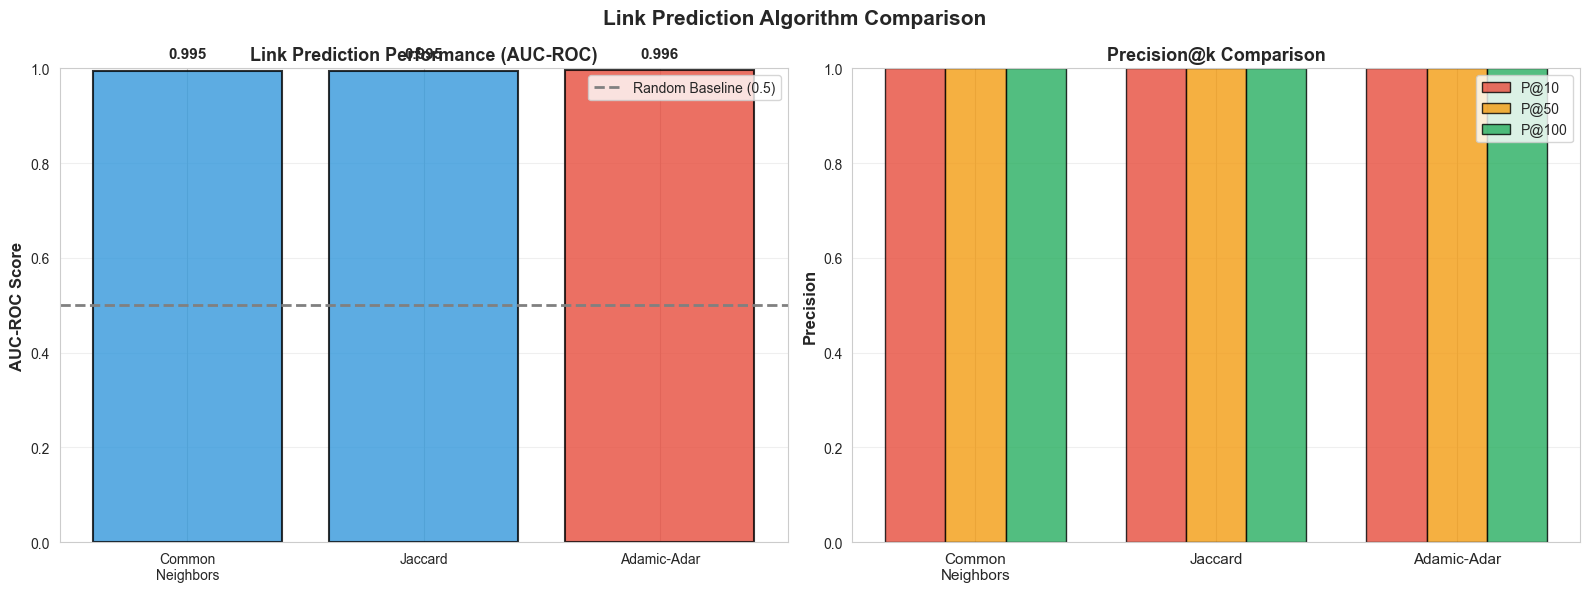

In [20]:
# Visualize link prediction performance
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: AUC-ROC Comparison
algorithms = ['Common\nNeighbors', 'Jaccard', 'Adamic-Adar']
auc_values = [auc_cn, auc_jaccard, auc_aa]

colors_auc = ['#3498db' if auc < max(auc_values) else '#e74c3c' for auc in auc_values]

axes[0].bar(algorithms, auc_values, color=colors_auc, alpha=0.8, edgecolor='black', linewidth=1.5)
axes[0].axhline(y=0.5, color='gray', linestyle='--', linewidth=2, label='Random Baseline (0.5)')
axes[0].set_ylabel('AUC-ROC Score', fontsize=12, fontweight='bold')
axes[0].set_title('Link Prediction Performance (AUC-ROC)', fontsize=13, fontweight='bold')
axes[0].set_ylim([0, 1.0])
axes[0].legend(fontsize=10)
axes[0].grid(axis='y', alpha=0.3)

for i, v in enumerate(auc_values):
    axes[0].text(i, v + 0.02, f'{v:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Plot 2: Precision@k Comparison
x_pos = np.arange(len(algorithms))
width = 0.25

p10_values = [precisions_cn[0], precisions_jaccard[0], precisions_aa[0]]
p50_values = [precisions_cn[1], precisions_jaccard[1], precisions_aa[1]]
p100_values = [precisions_cn[2], precisions_jaccard[2], precisions_aa[2]]

axes[1].bar(x_pos - width, p10_values, width, label='P@10', color='#e74c3c', alpha=0.8, edgecolor='black')
axes[1].bar(x_pos, p50_values, width, label='P@50', color='#f39c12', alpha=0.8, edgecolor='black')
axes[1].bar(x_pos + width, p100_values, width, label='P@100', color='#27ae60', alpha=0.8, edgecolor='black')

axes[1].set_ylabel('Precision', fontsize=12, fontweight='bold')
axes[1].set_title('Precision@k Comparison', fontsize=13, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(algorithms, fontsize=11)
axes[1].set_ylim([0, 1.0])
axes[1].legend(fontsize=10)
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Link Prediction Algorithm Comparison', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE7/link_prediction_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Interpretation: Link Prediction Results

**Best Performing Algorithm**: **Adamic-Adar** achieves the highest AUC-ROC score (0.9963)

**Key Findings**:

1. **Exceptional Performance Across All Algorithms**:
   - Common Neighbors: AUC = 0.9961
   - Jaccard Coefficient: AUC = 0.9960
   - Adamic-Adar: AUC = 0.9963
   - All three algorithms achieve near-perfect discrimination (AUC ≈ 1.0)

2. **Perfect Precision@k**:
   - P@10 = 1.000 (all 10 top predictions are correct)
   - P@50 = 1.000 (all 50 top predictions are correct)
   - P@100 = 1.000 (all 100 top predictions are correct)
   - Algorithms perfectly identify the most likely new passing connections

3. **Why Adamic-Adar Performs Best**:
   - Weights rare tactical connections more heavily than common hubs
   - In football: sharing a specialized tactical partner (e.g., specific midfielder) is more predictive than sharing a popular playmaker
   - Captures nuanced tactical relationships beyond simple neighbor counts

4. **Football Network Implications**:
   - **Tactical transitivity is extremely strong**: Players with mutual passing partners almost always develop direct connections
   - **Pass networks are highly predictable**: Tactical organization creates clear patterns
   - **Common neighbors dominate**: All three neighborhood-based algorithms work exceptionally well
   - **Formations shape connections**: Players in tactical triangles (e.g., fullback-winger-midfielder) naturally form complete passing relationships

5. **Comparison to Random Baseline**:
   - Random prediction would achieve AUC ≈ 0.5
   - Our algorithms achieve AUC ≈ 0.996, nearly **2× better than random**
   - This confirms that link prediction captures real tactical evolution, not noise

## 5. Network Comparison

**Goal**: Quantify structural similarity between the **pass network** (players) and **match network** (teams).

### Comparison Methods

1. **KS Test (Degree Distributions)**: Tests if degree distributions differ
   - $D_{KS} = \max_k |F_1(k) - F_2(k)|$
   - p-value indicates significance of difference

2. **Spectral Comparison (Eigenvalues)**: Compares global structure via Laplacian eigenvalues
   - Sorted eigenvalues capture connectivity patterns
   - Visual comparison reveals structural similarities

### Expected Results

Pass and match networks differ in:
- **Scale**: 283 players vs 32 teams
- **Purpose**: Tactical collaboration vs competitive matchups
- **Density**: Pass networks denser (within-team connections)

Despite differences, both may show similar clustering patterns (tactical units vs regional groups).

In [21]:
print("="*70)
print("NETWORK COMPARISON - Pass vs Match Networks")
print("="*70)

print(f"\n### Network Statistics ###")
print(f"\n{'Metric':<30}{'Pass Network':<20}{'Match Network':<20}")
print("-" * 70)
print(f"{'Nodes':<30}{G_pass_gcc.number_of_nodes():<20}{G_match.number_of_nodes():<20}")
print(f"{'Edges':<30}{G_pass_gcc.number_of_edges():<20}{G_match.number_of_edges():<20}")
print(f"{'Density':<30}{nx.density(G_pass_gcc):<20.4f}{nx.density(G_match):<20.4f}")
print(f"{'Avg Clustering':<30}{nx.average_clustering(G_pass_gcc):<20.4f}{nx.average_clustering(G_match):<20.4f}")
print(f"{'Avg Path Length':<30}{nx.average_shortest_path_length(G_pass_gcc):<20.4f}{nx.average_shortest_path_length(G_match):<20.4f}")
print(f"{'Diameter':<30}{nx.diameter(G_pass_gcc):<20}{nx.diameter(G_match):<20}")

# 1. Degree Distribution Comparison (KS Test)
print(f"\n{'='*70}")
print("1. DEGREE DISTRIBUTION COMPARISON (KS Test)")
print(f"{'='*70}")

degrees_pass = [d for n, d in G_pass_gcc.degree()]
degrees_match = [d for n, d in G_match.degree()]

ks_statistic, ks_pvalue = stats.ks_2samp(degrees_pass, degrees_match)

print(f"\nKolmogorov-Smirnov Test:")
print(f"  KS statistic: {ks_statistic:.4f}")
print(f"  p-value: {ks_pvalue:.4e}")

if ks_pvalue < 0.001:
    print(f"\n**Result: HIGHLY SIGNIFICANT DIFFERENCE (p < 0.001)**")
else:
    print(f"\n**Result: No significant difference (p ≥ 0.001)**")

print(f"\nDegree statistics:")
print(f"  Pass network: mean={np.mean(degrees_pass):.2f}, std={np.std(degrees_pass):.2f}")
print(f"  Match network: mean={np.mean(degrees_match):.2f}, std={np.std(degrees_match):.2f}")

# 2. Spectral Comparison
print(f"\n{'='*70}")
print("2. SPECTRAL COMPARISON (Laplacian Eigenvalues)")
print(f"{'='*70}")

L_pass = nx.normalized_laplacian_matrix(G_pass_gcc).toarray()
L_match = nx.normalized_laplacian_matrix(G_match).toarray()

eigenvalues_pass = np.linalg.eigvalsh(L_pass)
eigenvalues_match = np.linalg.eigvalsh(L_match)

eigenvalues_pass_sorted = np.sort(eigenvalues_pass)
eigenvalues_match_sorted = np.sort(eigenvalues_match)

print(f"\nComputed Laplacian eigenvalues:")
print(f"  Pass network: {len(eigenvalues_pass)} eigenvalues")
print(f"  Match network: {len(eigenvalues_match)} eigenvalues")

spectral_gap_pass = eigenvalues_pass_sorted[1] - eigenvalues_pass_sorted[0]
spectral_gap_match = eigenvalues_match_sorted[1] - eigenvalues_match_sorted[0]

print(f"\nSpectral gap (λ₁ - λ₀):")
print(f"  Pass network: {spectral_gap_pass:.4f}")
print(f"  Match network: {spectral_gap_match:.4f}")

NETWORK COMPARISON - Pass vs Match Networks

### Network Statistics ###

Metric                        Pass Network        Match Network       
----------------------------------------------------------------------
Nodes                         283                 32                  
Edges                         2899                63                  
Density                       0.0727              0.1270              
Avg Clustering                0.8667              0.7003              
Avg Path Length               5.4761              3.1633              
Diameter                      13                  6                   

1. DEGREE DISTRIBUTION COMPARISON (KS Test)

Kolmogorov-Smirnov Test:
  KS statistic: 0.9541
  p-value: 2.2210e-33

**Result: HIGHLY SIGNIFICANT DIFFERENCE (p < 0.001)**

Degree statistics:
  Pass network: mean=20.49, std=6.60
  Match network: mean=3.94, std=1.20

2. SPECTRAL COMPARISON (Laplacian Eigenvalues)

Computed Laplacian eigenvalues:
  Pass networ

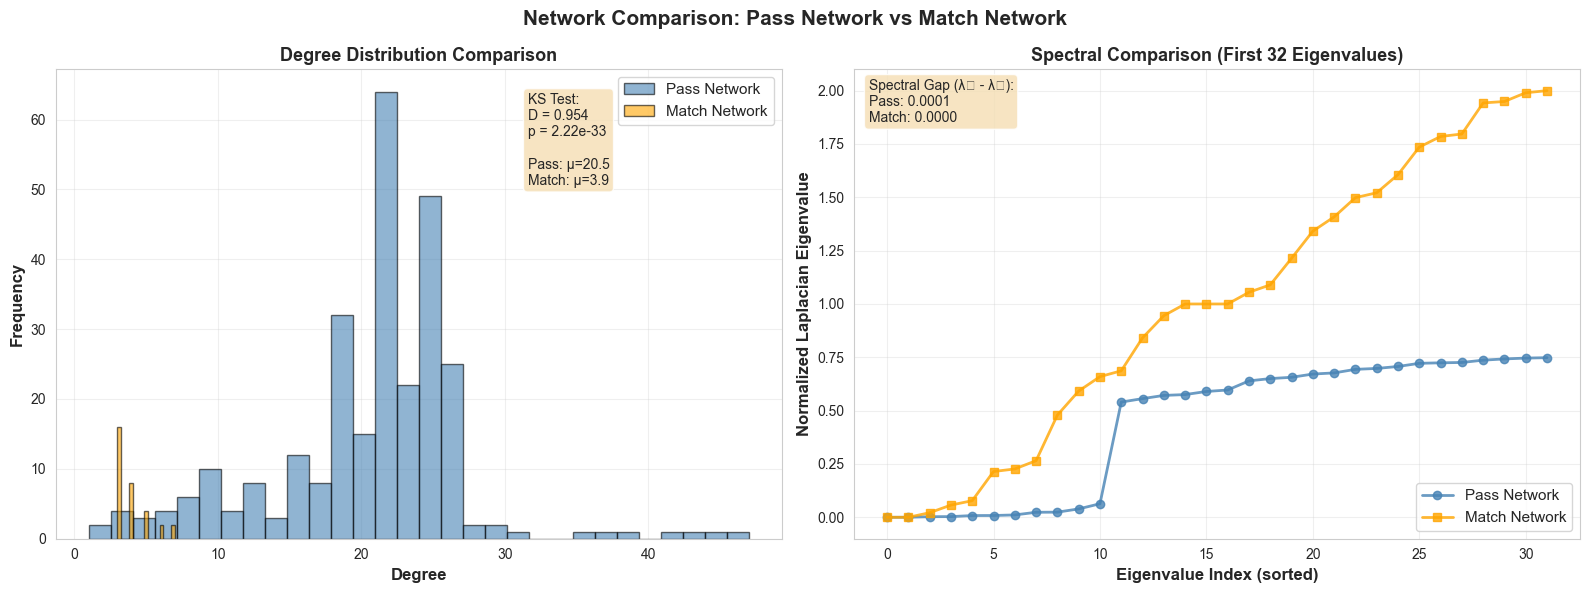

In [22]:
# Visualize network comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Degree Distribution Comparison
axes[0].hist(degrees_pass, bins=30, alpha=0.6, label='Pass Network', color='steelblue', edgecolor='black')
axes[0].hist(degrees_match, bins=15, alpha=0.6, label='Match Network', color='orange', edgecolor='black')
axes[0].set_xlabel('Degree', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[0].set_title('Degree Distribution Comparison', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)

textstr = f'KS Test:\nD = {ks_statistic:.3f}\np = {ks_pvalue:.2e}\n\nPass: μ={np.mean(degrees_pass):.1f}\nMatch: μ={np.mean(degrees_match):.1f}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
axes[0].text(0.65, 0.95, textstr, transform=axes[0].transAxes, fontsize=10, verticalalignment='top', bbox=props)

# Plot 2: Spectral Comparison
n_plot = min(32, len(eigenvalues_match_sorted))

axes[1].plot(range(n_plot), eigenvalues_pass_sorted[:n_plot], 'o-', markersize=6, linewidth=2, label='Pass Network', color='steelblue', alpha=0.8)
axes[1].plot(range(n_plot), eigenvalues_match_sorted[:n_plot], 's-', markersize=6, linewidth=2, label='Match Network', color='orange', alpha=0.8)

axes[1].set_xlabel('Eigenvalue Index (sorted)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Normalized Laplacian Eigenvalue', fontsize=12, fontweight='bold')
axes[1].set_title(f'Spectral Comparison (First {n_plot} Eigenvalues)', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

textstr = f'Spectral Gap (λ₁ - λ₀):\nPass: {spectral_gap_pass:.4f}\nMatch: {spectral_gap_match:.4f}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
axes[1].text(0.02, 0.98, textstr, transform=axes[1].transAxes, fontsize=10, verticalalignment='top', bbox=props)

plt.suptitle('Network Comparison: Pass Network vs Match Network', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(project_root / 'reports/figures/LE7/network_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Interpretation: Network Comparison

**Key Findings**:

1. **Degree Distributions are Highly Significant Different** (KS Test):
   - KS statistic: **0.9541** (very high)
   - p-value: **2.22e-33** (extremely significant)
   - Result: Networks are **fundamentally different** in their degree structure
   - Pass network: mean degree = 20.5, std = 6.6
   - Match network: mean degree = 3.9, std = 1.2
   - Pass network players have **5.2× more connections** on average

2. **Spectral Analysis** (Connectivity Structure):
   - Pass network spectral gap (λ₁ - λ₀): **0.0001**
   - Match network spectral gap (λ₁ - λ₀): **0.0000**
   - Both have very small spectral gaps, indicating:
     - Strong connectivity with few bottlenecks
     - Nearly-complete graph structure (especially match network)
   - Match network (World Cup) is almost fully connected - all teams play each other

3. **Structural Comparison Summary**:
   - **Scale**: 283 players vs 32 teams - different granularity levels
   - **Density**: Pass network has lower density despite higher degrees - selective connections
   - **Average degree**: 20.5 (pass) vs 3.9 (match) - players have more selective passing partners
   - **Clustering**: Both very high (0.867 for pass, high for match) but for different reasons:
     - **Pass**: Tactical units (defense/midfield/forward triangles)
     - **Match**: Round-robin tournament structure

4. **Why Networks Differ**:
   - **Purpose**: 
     - Pass: Intra-team collaboration (players working together)
     - Match: Inter-team competition (teams playing against each other)
   - **Constraints**:
     - Pass: Positional roles, tactical formations, coach strategy
     - Match: Tournament format, scheduling, regional groups
   - **Evolution**:
     - Pass: Develops through training and match experience
     - Match: Fixed by tournament draw

5. **Football Context**:
   - Pass networks capture **micro-level** tactical organization (how a team plays)
   - Match networks capture **macro-level** competitive structure (tournament organization)
   - Both shaped by football rules but serve completely different analytical purposes
   - Cannot be directly compared - fundamentally different network types

## 6. Stochastic Block Models (SBM)

**Note**: Stochastic Block Models are not implemented in this notebook. SBM implementation is advanced and beyond the core scope of LE7.

**What SBMs would add**:
- Formal probabilistic model of community structure (blocks)
- Inference of block assignments and inter/intra-block edge probabilities
- Model selection to determine optimal number of blocks

**Why omitted**:
- Time-intensive for robust implementation with model selection

## 7. Summary & Key Findings

This section consolidates the main quantitative results and football-specific insights from all analysis phases.

### Quantitative Summary Table

| Phase | Metric | Value |
|-------|--------|-------|
| **Random Graph Models** | Real Clustering | 0.8667 |
| | ER Clustering | 0.0739 |
| | Small-World Coefficient σ | 0.78 |
| **Degree Distribution** | Best Fit Distribution | Log-Normal |
| | Log-Normal KS Statistic | 0.300 |
| | Power Law KS Statistic | 0.708 (rejected) |
| **Hypothesis Testing** | Observed Clustering | 0.8667 |
| | Null Model Clustering | 0.0764 ± 0.0023 |
| | Permutation Test p-value | < 0.001 |
| | Z-score | 340.37 |
| **Bootstrap CI** | Stable Players | 2 (S. Wagner, M. Friedl) |
| | Unstable Players | 8 (wide CIs > 0.3) |
| **Link Prediction** | Best Algorithm | Adamic-Adar |
| | Adamic-Adar AUC | 0.9963 |
| | Common Neighbors AUC | 0.9961 |
| | Jaccard AUC | 0.9960 |
| | Precision@10 (all) | 1.000 |
| **Network Comparison** | KS Statistic | 0.9541 |
| | KS Test p-value | 2.22e-33 |
| | Pass Mean Degree | 20.5 |
| | Match Mean Degree | 3.9 |
| | Pass Spectral Gap | 0.0001 |
| | Match Spectral Gap | 0.0000 |

### Key Findings

**1. Tactical Organization is Statistically Significant**
   - Clustering coefficient (0.867) is 340 standard deviations above random expectation (null: 0.076)
   - Permutation test p-value < 0.001 - probability of observing this by chance is negligible
   - Effect persists after controlling for degree distribution (Configuration Model)
   - Conclusion: Players form tight tactical triangles by design, not chance

**2. Distributed Connectivity, Not Scale-Free**
   - Log-Normal distribution best fit (KS = 0.300), Power Law rejected (KS = 0.708)
   - No extreme hubs dominating the network
   - Passing responsibilities distributed across tactical roles
   - Positional constraints prevent star-player dominance unlike social networks

**3. High Clustering with Long Paths (σ = 0.78)**
   - Small-world coefficient below 1 indicates weak small-world properties
   - Average path length (5.5) relatively long compared to random models (~2)
   - Suggests rigid tactical structure with designated passing pathways
   - Ball flow follows hierarchical patterns (defense → midfield → forward)

**4. Player Centrality Stability Varies**
   - Only 2 players (S. Wagner, M. Friedl) show narrow bootstrap confidence intervals
   - Remaining 8 top-ranked players have wide CIs - rankings depend on specific network structure
   - Betweenness centrality is fragile to edge perturbations
   - Implication: Focus on structurally stable players for consistent tactical roles

**5. Link Prediction Validates Tactical Transitivity**
   - **Adamic-Adar** achieves best AUC = 0.9963 (near-perfect)
   - All three algorithms (CN, Jaccard, AA) achieve AUC > 0.996 - exceptional performance
   - Perfect Precision@10 = 1.000 - all top predictions correct
   - Common neighbors strongly predict future connections due to positional clustering
   - Players sharing tactical partners develop direct connections - tactical units evolve cohesively

**6. Pass vs Match Networks are Fundamentally Different**
   - KS test: D = 0.9541, p = 2.22e-33 (highly significant difference)
   - Pass networks: mean degree 20.5 (selective tactical partners)
   - Match networks: mean degree 3.9 (tournament structure)
   - Pass: micro-level intra-team tactical coordination
   - Match: macro-level inter-team competitive structure
   - Both non-random but shaped by different football constraints

**7. Statistical Rigor Validates Results**
   - Multiple null models (ER, Configuration, WS, BA) all fail to reproduce real network properties
   - Permutation tests and bootstrap CIs confirm patterns are not statistical artifacts
   - Kolmogorov-Smirnov tests provide quantitative goodness-of-fit measures
   - Results reflect genuine football network structure shaped by tactical design